In [2]:
# CELL 1: Setup and database connection
# ============================================

import os
import sqlite3
import pandas as pd
import numpy as np

# Update this path if the database is in another folder
DB_PATH = "echis_analyst_assessment.db"

if not os.path.exists(DB_PATH):
    raise FileNotFoundError(
        f"Database not found at: {DB_PATH}\n"
        "Place echis_analyst_assessment.db in the same folder as this notebook "
        "or update DB_PATH."
    )

conn = sqlite3.connect(DB_PATH)

print("Libraries loaded successfully.")
print(f"Connected to database: {DB_PATH}")

Libraries loaded successfully.
Connected to database: echis_analyst_assessment.db


In [3]:
# CELL 2: Inspect available tables
# ============================================

tables = pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name
""", conn)

tables

,name
0,chus
1,chws
2,clients
3,households
4,referrals
5,visits


In [4]:
# ============================================
# CELL 3: Load all tables
# ============================================

required_tables = [
    "chus",
    "chws",
    "households",
    "clients",
    "visits",
    "referrals"
]

available_tables = set(tables["name"])

missing_tables = [
    table for table in required_tables
    if table not in available_tables
]

if missing_tables:
    raise ValueError(
        f"The following required tables are missing: {missing_tables}\n"
        f"Available tables are: {sorted(available_tables)}"
    )

data = {}

for table_name in required_tables:
    data[table_name] = pd.read_sql_query(
        f"SELECT * FROM {table_name}",
        conn
    )

# Convenient individual DataFrames
chus = data["chus"].copy()
chws = data["chws"].copy()
households = data["households"].copy()
clients = data["clients"].copy()
visits = data["visits"].copy()
referrals = data["referrals"].copy()

# Display table sizes
row_counts = pd.DataFrame({
    "table": required_tables,
    "rows": [len(data[table]) for table in required_tables],
    "columns": [data[table].shape[1] for table in required_tables]
})

row_counts

,table,rows,columns
0,chus,20,6
1,chws,76,5
2,households,2500,5
3,clients,10104,7
4,visits,26771,17
5,referrals,1046,11


In [5]:
# ============================================
# CELL 4: Preview the visits table
# ============================================

visits.head(10)

,visit_id,client_id,chu_id,county,chw_id,module,visit_date,danger_sign_present,rdt_result,act_dispensed,antigen,status,muac_cm,oedema_present,classification,anc_contact_number,pnc_visit_number
0,V-0012757,CL-004934,CHU-KSM-02,Kisumu,CHV-0006,Malnutrition_Screening,2025-07-06,NaN,None,NaN,None,None,14.7,0.0,Normal,NaN,NaN
1,V-0018444,CL-007110,CHU-KAK-02,Kakamega,CHV-0023,Malnutrition_Screening,2025-08-22,NaN,None,NaN,None,None,15.1,0.0,Normal,NaN,NaN
2,V-0024543,CL-009462,CHU-NYR-02,Nyeri,CHV-0068,PNC,2025-11-04,0.0,None,NaN,None,None,NaN,NaN,None,NaN,3.0
3,V-0013025,CL-005023,CHU-KAK-01,Kakamega,CHV-0017,Malaria_Case,2025-04-14,1.0,None,0.0,None,None,NaN,NaN,None,NaN,NaN
4,V-0007657,CL-002921,CHU-KLF-02,Kilifi,CHV-0044,ANC,2025-10-21,0.0,None,NaN,None,None,NaN,NaN,None,5.0,NaN
5,V-0014747,CL-005662,CHU-NYR-02,Nyeri,CHV-0072,ANC,2025-10-29,0.0,None,NaN,None,None,NaN,NaN,None,2.0,NaN
6,V-0016939,CL-006529,CHU-KLF-02,Kilifi,CHV-0044,Malnutrition_Screening,2025-04-29,NaN,None,NaN,None,None,11.6,0.0,MAM,NaN,NaN
7,V-0017041,CL-006559,CHU-KSM-02,Kisumu,CHV-0009,Malnutrition_Screening,2025-06-16,NaN,None,NaN,None,None,14.1,0.0,Normal,NaN,NaN
8,V-0013936,CL-005388,CHU-NYR-03,Nyeri,CHV-0076,Malnutrition_Screening,2025-02-01,NaN,None,NaN,None,None,15.5,0.0,Normal,NaN,NaN
9,V-0019833,CL-007654,CHU-KSM-02,Kisumu,CHV-0010,Malnutrition_Screening,2025-03-10,NaN,None,NaN,None,None,16.0,0.0,Normal,NaN,NaN


In [7]:
# ============================================
# CELL 5: Cleaning helper functions
# ============================================

def clean_text(series):
    return (
        series.astype("string")
        .str.strip()
        .replace({
            "": pd.NA,
            "nan": pd.NA,
            "None": pd.NA,
            "NULL": pd.NA
        })
    )


def clean_id(series):
    return clean_text(series).str.upper()


def clean_module(series):
    values = clean_text(series).str.lower()

    module_map = {
        "anc": "ANC",
        "pnc": "PNC",

        "immunization": "Immunization",
        "immunisation": "Immunization",

        "malnutrition_screening": "Malnutrition_Screening",
        "malnutrition screening": "Malnutrition_Screening",

        "malaria_case": "Malaria_Case",
        "malaria case": "Malaria_Case"
    }

    return values.replace(module_map)


def clean_boolean(series):
    values = clean_text(series).str.lower()

    boolean_map = {
        "true": True,
        "1": True,
        "yes": True,

        "false": False,
        "0": False,
        "no": False
    }

    return values.replace(boolean_map)


def clean_referral_outcome(series):
    values = clean_text(series).str.lower()

    outcome_map = {
        "completed": "completed",
        "complete": "completed",
        "yes": "completed",
        "1": "completed",

        "not completed": "not_completed",
        "not_completed": "not_completed",
        "no": "not_completed",
        "0": "not_completed",

        "unknown": "unknown"
    }

    return values.replace(outcome_map)

In [8]:
# ============================================
# CELL 6: Clean reference tables
# ============================================

chus_clean = chus.copy()
chws_clean = chws.copy()
clients_clean = clients.copy()
households_clean = households.copy()

for df, columns in [
    (chus_clean, ["chu_id"]),
    (chws_clean, ["chw_id", "chu_id"]),
    (clients_clean, ["client_id", "household_id", "chu_id"]),
    (households_clean, ["household_id", "chu_id"])
]:
    for column in columns:
        df[f"{column}_clean"] = clean_id(df[column])

print("Reference tables cleaned.")

Reference tables cleaned.


In [9]:
# ============================================
# CELL 7: Clean visits
# ============================================

visits_clean = visits.copy()

# Clean identifiers
for column in ["visit_id", "client_id", "chu_id", "chw_id"]:
    visits_clean[f"{column}_clean"] = clean_id(visits_clean[column])

# Clean categories
visits_clean["module_clean"] = clean_module(visits_clean["module"])

visits_clean["danger_sign_present_clean"] = clean_boolean(
    visits_clean["danger_sign_present"]
)

visits_clean["oedema_present_clean"] = clean_boolean(
    visits_clean["oedema_present"]
)

visits_clean["rdt_result_clean"] = (
    clean_text(visits_clean["rdt_result"])
    .str.lower()
)

visits_clean["act_dispensed_clean"] = clean_boolean(
    visits_clean["act_dispensed"]
)

visits_clean["status_clean"] = (
    clean_text(visits_clean["status"])
    .str.lower()
)

visits_clean["classification_clean"] = (
    clean_text(visits_clean["classification"])
    .str.upper()
)

# Clean dates
visits_clean["visit_date_clean"] = pd.to_datetime(
    visits_clean["visit_date"],
    errors="coerce"
)

# Clean numeric fields
numeric_columns = [
    "muac_cm",
    "anc_contact_number",
    "pnc_visit_number"
]

for column in numeric_columns:
    visits_clean[f"{column}_clean"] = pd.to_numeric(
        visits_clean[column],
        errors="coerce"
    )

print("Visits table cleaned.")
visits_clean.head()

Visits table cleaned.


,visit_id,client_id,chu_id,county,chw_id,module,visit_date,danger_sign_present,rdt_result,act_dispensed,...,danger_sign_present_clean,oedema_present_clean,rdt_result_clean,act_dispensed_clean,status_clean,classification_clean,visit_date_clean,muac_cm_clean,anc_contact_number_clean,pnc_visit_number_clean
0,V-0012757,CL-004934,CHU-KSM-02,Kisumu,CHV-0006,Malnutrition_Screening,2025-07-06,NaN,None,NaN,...,<NA>,0.0,<NA>,<NA>,<NA>,NORMAL,2025-07-06,14.7,NaN,NaN
1,V-0018444,CL-007110,CHU-KAK-02,Kakamega,CHV-0023,Malnutrition_Screening,2025-08-22,NaN,None,NaN,...,<NA>,0.0,<NA>,<NA>,<NA>,NORMAL,2025-08-22,15.1,NaN,NaN
2,V-0024543,CL-009462,CHU-NYR-02,Nyeri,CHV-0068,PNC,2025-11-04,0.0,None,NaN,...,0.0,<NA>,<NA>,<NA>,<NA>,<NA>,2025-11-04,NaN,NaN,3.0
3,V-0013025,CL-005023,CHU-KAK-01,Kakamega,CHV-0017,Malaria_Case,2025-04-14,1.0,None,0.0,...,1.0,<NA>,<NA>,0.0,<NA>,<NA>,2025-04-14,NaN,NaN,NaN
4,V-0007657,CL-002921,CHU-KLF-02,Kilifi,CHV-0044,ANC,2025-10-21,0.0,None,NaN,...,0.0,<NA>,<NA>,<NA>,<NA>,<NA>,2025-10-21,NaN,5.0,NaN


In [10]:
# ============================================
# CELL 8: Clean referrals
# ============================================

referrals_clean = referrals.copy()

# Clean identifiers
for column in ["referral_id", "visit_id", "client_id", "chu_id"]:
    referrals_clean[f"{column}_clean"] = clean_id(
        referrals_clean[column]
    )

# Clean categories
referrals_clean["module_clean"] = clean_module(
    referrals_clean["module"]
)

referrals_clean["outcome_clean"] = clean_referral_outcome(
    referrals_clean["outcome"]
)

# Clean dates
referrals_clean["referral_date_clean"] = pd.to_datetime(
    referrals_clean["referral_date"],
    errors="coerce"
)

referrals_clean["completion_date_clean"] = pd.to_datetime(
    referrals_clean["completion_date"],
    errors="coerce"
)

print("Referrals table cleaned.")
referrals_clean.head()

Referrals table cleaned.


,referral_id,visit_id,client_id,chu_id,county,module,referral_reason,referral_date,facility_name,outcome,completion_date,referral_id_clean,visit_id_clean,client_id_clean,chu_id_clean,module_clean,outcome_clean,referral_date_clean,completion_date_clean
0,R-001019,V-0025338,CL-009785,CHU-KAK-02,Kakamega,ANC,ANC danger sign,2025-11-04,Kakamega Referral Health Centre,completed,2025-11-07,R-001019,V-0025338,CL-009785,CHU-KAK-02,ANC,completed,2025-11-04,2025-11-07
1,R-000737,V-0018330,CL-007073,CHU-BGM-02,Bungoma,ANC,ANC danger sign,2025-09-15,Bungoma Referral Health Centre,Not Completed,None,R-000737,V-0018330,CL-007073,CHU-BGM-02,ANC,not_completed,2025-09-15,NaT
2,R-000315,V-0007136,CL-002724,CHU-KLF-02,Kilifi,Malnutrition_Screening,SAM classification,2025-11-14,Kilifi Level 4 Hospital,Yes,2025-11-18,R-000315,V-0007136,CL-002724,CHU-KLF-02,Malnutrition_Screening,completed,2025-11-14,2025-11-18
3,R-000816,V-0020069,CL-007733,CHU-BGM-02,Bungoma,Malaria_Case,Severe malaria danger sign,2025-04-19,Bungoma Sub-County Hospital,Yes,2025-04-23,R-000816,V-0020069,CL-007733,CHU-BGM-02,Malaria_Case,completed,2025-04-19,2025-04-23
4,R-000979,V-0024587,CL-009485,CHU-KAK-02,Kakamega,Malaria_Case,Severe malaria danger sign,2025-01-04,Kakamega Referral Health Centre,Yes,2025-01-10,R-000979,V-0024587,CL-009485,CHU-KAK-02,Malaria_Case,completed,2025-01-04,2025-01-10


In [11]:
# ============================================
# CELL 9: Duplicate checks
# ============================================

duplicate_report = pd.DataFrame({
    "category": [
        "Duplicate visit IDs",
        "Duplicate referral IDs",
        "Duplicate client IDs",
        "Duplicate household IDs",
        "Duplicate CHU IDs",
        "Duplicate CHW IDs"
    ],
    "affected_rows": [
        visits_clean["visit_id_clean"].duplicated(keep=False).sum(),
        referrals_clean["referral_id_clean"].duplicated(keep=False).sum(),
        clients_clean["client_id_clean"].duplicated(keep=False).sum(),
        households_clean["household_id_clean"].duplicated(keep=False).sum(),
        chus_clean["chu_id_clean"].duplicated(keep=False).sum(),
        chws_clean["chw_id_clean"].duplicated(keep=False).sum()
    ]
})

duplicate_report

,category,affected_rows
0,Duplicate visit IDs,0
1,Duplicate referral IDs,0
2,Duplicate client IDs,0
3,Duplicate household IDs,0
4,Duplicate CHU IDs,4
5,Duplicate CHW IDs,0


In [12]:
duplicate_visits = visits_clean[
    visits_clean["visit_id_clean"].duplicated(keep=False)
].sort_values("visit_id_clean")

duplicate_visits.head(20)

,visit_id,client_id,chu_id,county,chw_id,module,visit_date,danger_sign_present,rdt_result,act_dispensed,...,danger_sign_present_clean,oedema_present_clean,rdt_result_clean,act_dispensed_clean,status_clean,classification_clean,visit_date_clean,muac_cm_clean,anc_contact_number_clean,pnc_visit_number_clean


In [13]:
# ============================================
# CELL 10: Module-specific missingness
# ============================================

missingness_records = []

module_fields = {
    "Malaria_Case": [
        "rdt_result_clean",
        "act_dispensed_clean",
        "danger_sign_present_clean"
    ],
    "ANC": [
        "danger_sign_present_clean",
        "anc_contact_number_clean"
    ],
    "PNC": [
        "danger_sign_present_clean",
        "pnc_visit_number_clean"
    ],
    "Immunization": [
        "antigen",
        "status_clean"
    ],
    "Malnutrition_Screening": [
        "muac_cm_clean",
        "oedema_present_clean",
        "classification_clean"
    ]
}

for module, fields in module_fields.items():

    subset = visits_clean[
        visits_clean["module_clean"] == module
    ]

    for field in fields:
        missing_count = subset[field].isna().sum()
        total_count = len(subset)

        missingness_records.append({
            "module": module,
            "field": field,
            "total_records": total_count,
            "missing_records": missing_count,
            "missing_percent": round(
                missing_count / total_count * 100, 2
            ) if total_count > 0 else 0
        })

missingness_report = pd.DataFrame(missingness_records)

missingness_report

,module,field,total_records,missing_records,missing_percent
0,Malaria_Case,rdt_result_clean,5507,508,9.22
1,Malaria_Case,act_dispensed_clean,5507,0,0.00
2,Malaria_Case,danger_sign_present_clean,5507,0,0.00
3,ANC,danger_sign_present_clean,4534,0,0.00
4,ANC,anc_contact_number_clean,4534,0,0.00
5,PNC,danger_sign_present_clean,1265,0,0.00
6,PNC,pnc_visit_number_clean,1265,0,0.00
7,Immunization,antigen,8994,0,0.00
8,Immunization,status_clean,8994,0,0.00
9,Malnutrition_Screening,muac_cm_clean,6420,256,3.99


In [14]:
# ============================================
# CELL 11: Invalid and impossible values
# ============================================

# Invalid MUAC values
invalid_muac = visits_clean[
    visits_clean["muac_cm_clean"].notna()
    & (
        (visits_clean["muac_cm_clean"] <= 0)
        | (visits_clean["muac_cm_clean"] > 40)
    )
].copy()

# Invalid ANC contact numbers
invalid_anc_contacts = visits_clean[
    visits_clean["anc_contact_number_clean"].notna()
    & (
        visits_clean["anc_contact_number_clean"] <= 0
    )
].copy()

# Invalid PNC visit numbers
invalid_pnc_visits = visits_clean[
    visits_clean["pnc_visit_number_clean"].notna()
    & (
        visits_clean["pnc_visit_number_clean"] <= 0
    )
].copy()

invalid_values_report = pd.DataFrame({
    "issue": [
        "Invalid MUAC",
        "Invalid ANC contact number",
        "Invalid PNC visit number"
    ],
    "affected_rows": [
        len(invalid_muac),
        len(invalid_anc_contacts),
        len(invalid_pnc_visits)
    ]
})

invalid_values_report

,issue,affected_rows
0,Invalid MUAC,64
1,Invalid ANC contact number,0
2,Invalid PNC visit number,0


In [15]:
invalid_muac[
    [
        "visit_id",
        "client_id",
        "visit_date",
        "muac_cm",
        "classification"
    ]
].head(20)

,visit_id,client_id,visit_date,muac_cm,classification
476,V-0006460,CL-002459,2025-03-31,999.0,MAM
477,V-0015520,CL-005960,2025-03-26,0.0,Normal
1498,V-0006873,CL-002616,2025-12-11,999.0,Normal
1852,V-0023395,CL-009004,2025-09-14,999.0,Normal
1881,V-0013974,CL-005397,2025-06-01,0.0,SAM
2029,V-0026476,CL-000263,2025-05-02,999.0,Normal
3215,V-0005634,CL-002120,2025-11-28,0.0,Normal
3551,V-0011415,CL-004395,2025-01-18,0.0,MAM
3834,V-0019671,CL-007594,2025-02-01,999.0,Normal
4194,V-0022250,CL-008569,2025-03-19,0.0,Normal


In [16]:
# ============================================
# CELL 12: Date checks
# ============================================

analysis_start = pd.Timestamp("2025-01-01")
analysis_end = pd.Timestamp("2025-12-31")

date_quality_report = pd.DataFrame({
    "issue": [
        "Visits outside 2025",
        "Referrals outside 2025",
        "Missing visit dates",
        "Missing referral dates",
        "Missing referral completion dates"
    ],
    "affected_rows": [
        (~visits_clean["visit_date_clean"].between(
            analysis_start,
            analysis_end
        )).sum(),

        (~referrals_clean["referral_date_clean"].between(
            analysis_start,
            analysis_end
        )).sum(),

        visits_clean["visit_date_clean"].isna().sum(),
        referrals_clean["referral_date_clean"].isna().sum(),
        referrals_clean["completion_date_clean"].isna().sum()
    ]
})

date_quality_report

,issue,affected_rows
0,Visits outside 2025,103
1,Referrals outside 2025,0
2,Missing visit dates,0
3,Missing referral dates,0
4,Missing referral completion dates,356


In [18]:
invalid_referral_dates = referrals_clean[
    referrals_clean["completion_date_clean"].notna()
    & referrals_clean["referral_date_clean"].notna()
    & (
        referrals_clean["completion_date_clean"]
        < referrals_clean["referral_date_clean"]
    )
].copy()

print(
    "Completion before referral:",
    len(invalid_referral_dates)
)

invalid_referral_dates[
    [
        "referral_id",
        "referral_date",
        "completion_date",
        "outcome"
    ]
].head(20)


Completion before referral: 6


,referral_id,referral_date,completion_date,outcome
219,R-000571,2025-06-02,2025-05-30,yes
280,R-000031,2025-11-25,2025-11-21,Yes
291,R-000803,2025-10-04,2025-10-03,Yes
483,R-000391,2025-10-22,2025-10-19,1
535,R-000815,2025-04-16,2025-04-12,Completed
708,R-000387,2025-07-04,2025-07-01,yes


In [19]:
# ============================================
# CELL 13: Category normalization report
# ============================================

category_report = {
    "raw_modules": sorted(
        visits["module"]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
        .tolist()
    ),

    "clean_modules": sorted(
        visits_clean["module_clean"]
        .dropna()
        .unique()
        .tolist()
    ),

    "raw_referral_outcomes": sorted(
        referrals["outcome"]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
        .unique()
        .tolist()
    ),

    "clean_referral_outcomes": sorted(
        referrals_clean["outcome_clean"]
        .dropna()
        .unique()
        .tolist()
    )
}

category_report

{'raw_modules': ['ANC',
  'Anc',
  'IMMUNIZATION',
  'Immunisation',
  'Immunization',
  'MALNUTRITION_SCREENING',
  'Malaria Case',
  'Malaria_Case',
  'Malnutrition Screening',
  'Malnutrition_Screening',
  'Malria_Case',
  'PNC',
  'Pnc',
  'anc',
  'immunization',
  'malaria_case',
  'malnutrition_screening',
  'pnc'],
 'clean_modules': ['ANC',
  'Immunization',
  'Malaria_Case',
  'Malnutrition_Screening',
  'PNC',
  'malria_case'],
 'raw_referral_outcomes': ['0',
  '1',
  'completed',
  'n/a',
  'na',
  'no',
  'not completed',
  'not_completed',
  'unknown',
  'yes'],
 'clean_referral_outcomes': ['completed',
  'n/a',
  'na',
  'not_completed',
  'unknown']}

In [20]:
# ============================================
# CELL 14: Referential integrity checks
# ============================================

valid_chu_ids = set(chus_clean["chu_id_clean"].dropna())
valid_chw_ids = set(chws_clean["chw_id_clean"].dropna())
valid_client_ids = set(clients_clean["client_id_clean"].dropna())
valid_visit_ids = set(visits_clean["visit_id_clean"].dropna())

referential_integrity_report = pd.DataFrame({
    "check": [
        "Visits with unknown CHU",
        "Visits with unknown CHW",
        "Visits with unknown client",
        "Referrals with unknown visit",
        "Referrals with unknown client"
    ],
    "affected_rows": [
        (~visits_clean["chu_id_clean"].isin(
            valid_chu_ids
        )).sum(),

        (~visits_clean["chw_id_clean"].isin(
            valid_chw_ids
        )).sum(),

        (~visits_clean["client_id_clean"].isin(
            valid_client_ids
        )).sum(),

        (~referrals_clean["visit_id_clean"].isin(
            valid_visit_ids
        )).sum(),

        (~referrals_clean["client_id_clean"].isin(
            valid_client_ids
        )).sum()
    ]
})

referential_integrity_report

,check,affected_rows
0,Visits with unknown CHU,0
1,Visits with unknown CHW,0
2,Visits with unknown client,80
3,Referrals with unknown visit,0
4,Referrals with unknown client,0


In [21]:
# ============================================
# CELL 15: Cross-table consistency
# ============================================

client_to_chu = dict(
    zip(
        clients_clean["client_id_clean"],
        clients_clean["chu_id_clean"]
    )
)

chw_to_chu = dict(
    zip(
        chws_clean["chw_id_clean"],
        chws_clean["chu_id_clean"]
    )
)

visit_client_chu = visits_clean["client_id_clean"].map(
    client_to_chu
)

visit_chw_chu = visits_clean["chw_id_clean"].map(
    chw_to_chu
)

visits_clean["flag_client_chu_mismatch"] = (
    visit_client_chu != visits_clean["chu_id_clean"]
).fillna(True)

visits_clean["flag_chw_chu_mismatch"] = (
    visit_chw_chu != visits_clean["chu_id_clean"]
).fillna(True)

visit_to_chu = dict(
    zip(
        visits_clean["visit_id_clean"],
        visits_clean["chu_id_clean"]
    )
)

visit_to_client = dict(
    zip(
        visits_clean["visit_id_clean"],
        visits_clean["client_id_clean"]
    )
)

referrals_clean["flag_visit_chu_mismatch"] = (
    referrals_clean["visit_id_clean"].map(visit_to_chu)
    != referrals_clean["chu_id_clean"]
).fillna(True)

referrals_clean["flag_visit_client_mismatch"] = (
    referrals_clean["visit_id_clean"].map(visit_to_client)
    != referrals_clean["client_id_clean"]
).fillna(True)

cross_table_report = pd.DataFrame({
    "check": [
        "Visit CHU differs from client CHU",
        "Visit CHU differs from CHW CHU",
        "Referral CHU differs from visit CHU",
        "Referral client differs from visit client"
    ],
    "affected_rows": [
        visits_clean["flag_client_chu_mismatch"].sum(),
        visits_clean["flag_chw_chu_mismatch"].sum(),
        referrals_clean["flag_visit_chu_mismatch"].sum(),
        referrals_clean["flag_visit_client_mismatch"].sum()
    ]
})

cross_table_report

,check,affected_rows
0,Visit CHU differs from client CHU,80
1,Visit CHU differs from CHW CHU,0
2,Referral CHU differs from visit CHU,0
3,Referral client differs from visit client,1


In [22]:
# ============================================
# CELL 16: Final quality flags
# ============================================

visits_clean["flag_out_of_period"] = ~visits_clean[
    "visit_date_clean"
].between(analysis_start, analysis_end)

visits_clean["flag_duplicate_visit_id"] = (
    visits_clean["visit_id_clean"]
    .duplicated(keep=False)
)

visits_clean["flag_invalid_muac"] = (
    visits_clean["muac_cm_clean"].notna()
    & (
        (visits_clean["muac_cm_clean"] <= 0)
        | (visits_clean["muac_cm_clean"] > 40)
    )
)

visits_clean["flag_missing_rdt"] = (
    visits_clean["module_clean"].eq("Malaria_Case")
    & visits_clean["rdt_result_clean"].isna()
)

visits_clean["flag_unknown_client"] = ~visits_clean[
    "client_id_clean"
].isin(valid_client_ids)

visits_clean["flag_unknown_chw"] = ~visits_clean[
    "chw_id_clean"
].isin(valid_chw_ids)

visits_clean["flag_unknown_chu"] = ~visits_clean[
    "chu_id_clean"
].isin(valid_chu_ids)

visit_flag_columns = [
    column for column in visits_clean.columns
    if column.startswith("flag_")
]

visits_clean["any_quality_flag"] = visits_clean[
    visit_flag_columns
].any(axis=1)

referrals_clean["flag_out_of_period"] = ~referrals_clean[
    "referral_date_clean"
].between(analysis_start, analysis_end)

referrals_clean["flag_duplicate_referral_id"] = (
    referrals_clean["referral_id_clean"]
    .duplicated(keep=False)
)

referrals_clean["flag_unknown_outcome"] = (
    referrals_clean["outcome_clean"].isna()
    | referrals_clean["outcome_clean"].eq("unknown")
)

referrals_clean["flag_invalid_date_order"] = (
    referrals_clean["completion_date_clean"].notna()
    & referrals_clean["referral_date_clean"].notna()
    & (
        referrals_clean["completion_date_clean"]
        < referrals_clean["referral_date_clean"]
    )
)

referrals_clean["flag_unknown_visit"] = ~referrals_clean[
    "visit_id_clean"
].isin(valid_visit_ids)

referrals_clean["flag_unknown_client"] = ~referrals_clean[
    "client_id_clean"
].isin(valid_client_ids)

referral_flag_columns = [
    column for column in referrals_clean.columns
    if column.startswith("flag_")
]

referrals_clean["any_quality_flag"] = referrals_clean[
    referral_flag_columns
].any(axis=1)

print("Visit flags created:", len(visit_flag_columns))
print("Referral flags created:", len(referral_flag_columns))

Visit flags created: 9
Referral flags created: 8


In [23]:
# ============================================
# CELL 17: Task A summary report
# ============================================

task_a_summary = pd.concat([
    duplicate_report.rename(
        columns={
            "category": "issue",
            "affected_rows": "affected_records"
        }
    )[["issue", "affected_records"]],

    invalid_values_report.rename(
        columns={
            "affected_rows": "affected_records"
        }
    )[["issue", "affected_records"]],

    date_quality_report.rename(
        columns={
            "affected_rows": "affected_records"
        }
    )[["issue", "affected_records"]],

    referential_integrity_report.rename(
        columns={
            "check": "issue",
            "affected_rows": "affected_records"
        }
    )[["issue", "affected_records"]],

    cross_table_report.rename(
        columns={
            "check": "issue",
            "affected_rows": "affected_records"
        }
    )[["issue", "affected_records"]]
], ignore_index=True)

task_a_summary

,issue,affected_records
0,Duplicate visit IDs,0
1,Duplicate referral IDs,0
2,Duplicate client IDs,0
3,Duplicate household IDs,0
4,Duplicate CHU IDs,4
5,Duplicate CHW IDs,0
6,Invalid MUAC,64
7,Invalid ANC contact number,0
8,Invalid PNC visit number,0
9,Visits outside 2025,103


In [24]:
# ============================================
# CELL 18: Export cleaned data and reports
# ============================================

visits_clean.to_csv(
    "visits_clean.csv",
    index=False
)

referrals_clean.to_csv(
    "referrals_clean.csv",
    index=False
)

task_a_summary.to_csv(
    "task_a_summary.csv",
    index=False
)

missingness_report.to_csv(
    "task_a_missingness_report.csv",
    index=False
)

print("Task A outputs saved successfully.")

Task A outputs saved successfully.


In [25]:
# ============================================
# CELL 19: Task B setup
# ============================================

analysis_start = pd.Timestamp("2025-01-01")
analysis_end = pd.Timestamp("2025-12-31")

# Work only with valid 2025 records
visits_b = visits_clean[
    visits_clean["visit_date_clean"].between(
        analysis_start,
        analysis_end
    )
].copy()

referrals_b = referrals_clean[
    referrals_clean["referral_date_clean"].between(
        analysis_start,
        analysis_end
    )
].copy()

# Avoid duplicate CHU rows in the lookup table
chus_lookup = (
    chus_clean[
        [
            "chu_id_clean",
            "chu_name",
            "county",
            "sub_county",
            "ward"
        ]
    ]
    .drop_duplicates("chu_id_clean")
)

# Avoid duplicate CHW rows in the lookup table
chws_lookup = (
    chws_clean[
        [
            "chw_id_clean",
            "chw_name",
            "chu_id_clean"
        ]
    ]
    .drop_duplicates("chw_id_clean")
)

def safe_rate(numerator, denominator):
    return np.where(
        denominator > 0,
        numerator / denominator * 100,
        np.nan
    )

print("2025 visits:", len(visits_b))
print("2025 referrals:", len(referrals_b))

2025 visits: 26668
2025 referrals: 1046


In [27]:
# ============================================
# CELL 20: Malaria performance by CHU
# ============================================

malaria = visits_b[
    visits_b["module_clean"] == "Malaria_Case"
].copy()

# RDT was actually done only when result is positive or negative
malaria["rdt_done"] = malaria[
    "rdt_result_clean"
].isin(["positive", "negative"])

malaria["rdt_positive"] = malaria[
    "rdt_result_clean"
].eq("positive")

malaria["act_dispensed_flag"] = malaria[
    "act_dispensed_clean"
].eq(True)

# Aggregate all malaria visits by CHU
malaria_by_chu = (
    malaria
    .groupby("chu_id_clean")
    .agg(
        malaria_visits=("visit_id_clean", "count"),
        rdt_tested=("rdt_done", "sum"),
        rdt_positive=("rdt_positive", "sum")
    )
    .reset_index()
)

# ACT dispensing among positive cases only
act_by_chu = (
    malaria[malaria["rdt_positive"]]
    .groupby("chu_id_clean")
    .agg(
        positive_act_dispensed=("act_dispensed_flag", "sum")
    )
    .reset_index()
)

malaria_by_chu = malaria_by_chu.merge(
    act_by_chu,
    on="chu_id_clean",
    how="left"
)

malaria_by_chu["positive_act_dispensed"] = (
    malaria_by_chu["positive_act_dispensed"]
    .fillna(0)
)

# Calculate percentages
malaria_by_chu["rdt_positivity_rate_pct"] = safe_rate(
    malaria_by_chu["rdt_positive"],
    malaria_by_chu["rdt_tested"]
)

malaria_by_chu["act_dispensing_rate_positive_pct"] = safe_rate(
    malaria_by_chu["positive_act_dispensed"],
    malaria_by_chu["rdt_positive"]
)

# Add CHU labels
malaria_by_chu = malaria_by_chu.merge(
    chus_lookup,
    on="chu_id_clean",
    how="left"
)

malaria_by_chu = malaria_by_chu[
    [
        "chu_id_clean",
        "chu_name",
        "county",
        "malaria_visits",
        "rdt_tested",
        "rdt_positive",
        "rdt_positivity_rate_pct",
        "positive_act_dispensed",
        "act_dispensing_rate_positive_pct"
    ]
].sort_values(
    "malaria_visits",
    ascending=False
)

malaria_by_chu

,chu_id_clean,chu_name,county,malaria_visits,rdt_tested,rdt_positive,rdt_positivity_rate_pct,positive_act_dispensed,act_dispensing_rate_positive_pct
4,CHU-KAK-02,Kakamega CHU 2,Kakamega,703,648,220,33.950617,0,0.0
16,CHU-NYR-02,Nyeri CHU 2,Nyeri,686,621,217,34.943639,0,0.0
17,CHU-NYR-03,Nyeri CHU 3,Nyeri,447,403,144,35.732010,0,0.0
6,CHU-KLF-01,Kilifi CHU 1,Kilifi,444,397,146,36.775819,0,0.0
3,CHU-KAK-01,Kakamega CHU 1,Kakamega,379,345,131,37.971014,0,0.0
10,CHU-KSM-02,Kisumu CHU 2,Kisumu,371,338,124,36.686391,0,0.0
7,CHU-KLF-02,Kilifi CHU 2,Kilifi,329,303,105,34.653465,0,0.0
1,CHU-BGM-02,Bungoma CHU 2,Bungoma,319,288,102,35.416667,0,0.0
5,CHU-KAK-03,Kakamega CHU 3,Kakamega,304,282,101,35.815603,0,0.0
0,CHU-BGM-01,Bungoma CHU 1,Bungoma,276,255,91,35.686275,0,0.0


In [28]:
# ============================================
# CELL 21: Format malaria results
# ============================================

malaria_by_chu_display = malaria_by_chu.copy()

for column in [
    "rdt_positivity_rate_pct",
    "act_dispensing_rate_positive_pct"
]:
    malaria_by_chu_display[column] = (
        malaria_by_chu_display[column]
        .round(1)
    )

malaria_by_chu_display

,chu_id_clean,chu_name,county,malaria_visits,rdt_tested,rdt_positive,rdt_positivity_rate_pct,positive_act_dispensed,act_dispensing_rate_positive_pct
4,CHU-KAK-02,Kakamega CHU 2,Kakamega,703,648,220,34.0,0,0.0
16,CHU-NYR-02,Nyeri CHU 2,Nyeri,686,621,217,34.9,0,0.0
17,CHU-NYR-03,Nyeri CHU 3,Nyeri,447,403,144,35.7,0,0.0
6,CHU-KLF-01,Kilifi CHU 1,Kilifi,444,397,146,36.8,0,0.0
3,CHU-KAK-01,Kakamega CHU 1,Kakamega,379,345,131,38.0,0,0.0
10,CHU-KSM-02,Kisumu CHU 2,Kisumu,371,338,124,36.7,0,0.0
7,CHU-KLF-02,Kilifi CHU 2,Kilifi,329,303,105,34.7,0,0.0
1,CHU-BGM-02,Bungoma CHU 2,Bungoma,319,288,102,35.4,0,0.0
5,CHU-KAK-03,Kakamega CHU 3,Kakamega,304,282,101,35.8,0,0.0
0,CHU-BGM-01,Bungoma CHU 1,Bungoma,276,255,91,35.7,0,0.0


In [29]:
malaria_by_chu.to_csv(
    "task_b1_malaria_performance_by_chu.csv",
    index=False
)

In [30]:
# ============================================
# CELL 22: Referral completion by module
# ============================================

referrals_b["known_outcome"] = referrals_b[
    "outcome_clean"
].isin([
    "completed",
    "not_completed"
])

referrals_b["completed_flag"] = referrals_b[
    "outcome_clean"
].eq("completed")

referrals_by_module = (
    referrals_b
    .groupby("module_clean")
    .agg(
        total_referrals=("referral_id_clean", "count"),
        completed_referrals=("completed_flag", "sum"),
        known_outcomes=("known_outcome", "sum")
    )
    .reset_index()
)

referrals_by_module["unknown_or_missing_outcomes"] = (
    referrals_by_module["total_referrals"]
    - referrals_by_module["known_outcomes"]
)

referrals_by_module["completion_rate_pct"] = safe_rate(
    referrals_by_module["completed_referrals"],
    referrals_by_module["known_outcomes"]
)

referrals_by_module = referrals_by_module.sort_values(
    "completion_rate_pct",
    ascending=False
)

referrals_by_module

,module_clean,total_referrals,completed_referrals,known_outcomes,unknown_or_missing_outcomes,completion_rate_pct
1,Malaria_Case,345,231,293,52,78.839590
0,ANC,332,215,282,50,76.241135
3,PNC,69,42,57,12,73.684211
2,Malnutrition_Screening,300,183,253,47,72.332016


In [31]:
# ============================================
# CELL 23: Referral completion by county
# ============================================

referrals_by_county = (
    referrals_b
    .groupby("county")
    .agg(
        total_referrals=("referral_id_clean", "count"),
        completed_referrals=("completed_flag", "sum"),
        known_outcomes=("known_outcome", "sum")
    )
    .reset_index()
)

referrals_by_county["unknown_or_missing_outcomes"] = (
    referrals_by_county["total_referrals"]
    - referrals_by_county["known_outcomes"]
)

referrals_by_county["completion_rate_pct"] = safe_rate(
    referrals_by_county["completed_referrals"],
    referrals_by_county["known_outcomes"]
)

referrals_by_county = referrals_by_county.sort_values(
    "completion_rate_pct",
    ascending=False
)

referrals_by_county

,county,total_referrals,completed_referrals,known_outcomes,unknown_or_missing_outcomes,completion_rate_pct
5,Nyeri,256,169,210,46,80.476190
4,Machakos,65,46,58,7,79.310345
3,Kisumu,149,97,127,22,76.377953
2,Kilifi,171,114,151,20,75.496689
1,Kakamega,259,160,221,38,72.398190
0,Bungoma,146,85,118,28,72.033898


In [32]:
# ============================================
# CELL 24: Referral completion by county and module
# ============================================

referrals_by_county_module = (
    referrals_b
    .groupby(["county", "module_clean"])
    .agg(
        total_referrals=("referral_id_clean", "count"),
        completed_referrals=("completed_flag", "sum"),
        known_outcomes=("known_outcome", "sum")
    )
    .reset_index()
)

referrals_by_county_module[
    "unknown_or_missing_outcomes"
] = (
    referrals_by_county_module["total_referrals"]
    - referrals_by_county_module["known_outcomes"]
)

referrals_by_county_module[
    "completion_rate_pct"
] = safe_rate(
    referrals_by_county_module["completed_referrals"],
    referrals_by_county_module["known_outcomes"]
)

referrals_by_county_module.sort_values(
    ["county", "completion_rate_pct"],
    ascending=[True, False]
)

,county,module_clean,total_referrals,completed_referrals,known_outcomes,unknown_or_missing_outcomes,completion_rate_pct
2,Bungoma,Malnutrition_Screening,46,26,34,12,76.470588
1,Bungoma,Malaria_Case,51,32,43,8,74.418605
0,Bungoma,ANC,40,24,34,6,70.588235
3,Bungoma,PNC,9,3,7,2,42.857143
4,Kakamega,ANC,83,58,74,9,78.378378
5,Kakamega,Malaria_Case,73,43,61,12,70.491803
7,Kakamega,PNC,17,9,13,4,69.230769
6,Kakamega,Malnutrition_Screening,86,50,73,13,68.493151
11,Kilifi,PNC,5,5,5,0,100.000000
9,Kilifi,Malaria_Case,63,42,54,9,77.777778


In [33]:
referrals_by_module.to_csv(
    "task_b2_referral_completion_by_module.csv",
    index=False
)

referrals_by_county.to_csv(
    "task_b2_referral_completion_by_county.csv",
    index=False
)

referrals_by_county_module.to_csv(
    "task_b2_referral_completion_by_county_module.csv",
    index=False
)

In [34]:
# ============================================
# CELL 25: CHV visit volume and active months
# ============================================

visits_b["active_month"] = (
    visits_b["visit_date_clean"]
    .dt.to_period("M")
)

chw_productivity = (
    visits_b
    .groupby("chw_id_clean")
    .agg(
        total_visits=("visit_id_clean", "count"),
        active_months=("active_month", "nunique"),
        first_active_month=("active_month", "min"),
        last_active_month=("active_month", "max")
    )
    .reset_index()
)

chw_productivity[
    "average_visits_per_active_month"
] = (
    chw_productivity["total_visits"]
    / chw_productivity["active_months"]
)

# Add CHV details
chw_productivity = chw_productivity.merge(
    chws_lookup,
    on="chw_id_clean",
    how="left"
)

# Add county and CHU details
chw_productivity = chw_productivity.merge(
    chus_lookup[
        [
            "chu_id_clean",
            "chu_name",
            "county"
        ]
    ],
    on="chu_id_clean",
    how="left",
    suffixes=("", "_from_chu")
)

# Top 5 by total visit volume
top_5_chvs = (
    chw_productivity
    .sort_values(
        [
            "total_visits",
            "average_visits_per_active_month"
        ],
        ascending=False
    )
    .head(5)
)

top_5_chvs

,chw_id_clean,total_visits,active_months,first_active_month,last_active_month,average_visits_per_active_month,chw_name,chu_id_clean,chu_name,county
20,CHV-0021,1232,12,2025-01,2025-12,102.666667,Kiplagat Mburu,CHU-KAK-02,Kakamega CHU 2,Kakamega
22,CHV-0023,1229,12,2025-01,2025-12,102.416667,Kiplagat Kilonzo,CHU-KAK-02,Kakamega CHU 2,Kakamega
21,CHV-0022,1205,12,2025-01,2025-12,100.416667,Wanjiru Njoroge,CHU-KAK-02,Kakamega CHU 2,Kakamega
41,CHV-0042,725,12,2025-01,2025-12,60.416667,Mutua Simiyu,CHU-KLF-01,Kilifi CHU 1,Kilifi
67,CHV-0068,719,12,2025-01,2025-12,59.916667,Wairimu Kilonzo,CHU-NYR-02,Nyeri CHU 2,Nyeri


In [35]:
# ============================================
# CELL 26: Format top-five CHV results
# ============================================

top_5_chvs_display = top_5_chvs.copy()

top_5_chvs_display[
    "average_visits_per_active_month"
] = (
    top_5_chvs_display[
        "average_visits_per_active_month"
    ].round(1)
)

top_5_chvs_display

,chw_id_clean,total_visits,active_months,first_active_month,last_active_month,average_visits_per_active_month,chw_name,chu_id_clean,chu_name,county
20,CHV-0021,1232,12,2025-01,2025-12,102.7,Kiplagat Mburu,CHU-KAK-02,Kakamega CHU 2,Kakamega
22,CHV-0023,1229,12,2025-01,2025-12,102.4,Kiplagat Kilonzo,CHU-KAK-02,Kakamega CHU 2,Kakamega
21,CHV-0022,1205,12,2025-01,2025-12,100.4,Wanjiru Njoroge,CHU-KAK-02,Kakamega CHU 2,Kakamega
41,CHV-0042,725,12,2025-01,2025-12,60.4,Mutua Simiyu,CHU-KLF-01,Kilifi CHU 1,Kilifi
67,CHV-0068,719,12,2025-01,2025-12,59.9,Wairimu Kilonzo,CHU-NYR-02,Nyeri CHU 2,Nyeri


In [36]:
chw_productivity.to_csv(
    "task_b3_chv_productivity_all.csv",
    index=False
)

top_5_chvs.to_csv(
    "task_b3_top_5_chvs.csv",
    index=False
)

In [39]:
# ============================================
# CELL 27: Save cleaned analytical tables to SQLite
# ============================================

def make_sqlite_safe(df):
    """
    Convert pandas-specific data types into values
    that SQLite can store safely.
    """
    output = df.copy()

    for column in output.columns:

        # Convert pandas Period values to text
        if isinstance(output[column].dtype, pd.PeriodDtype):
            output[column] = output[column].astype("string")

        # Convert datetime columns to ISO date strings
        elif pd.api.types.is_datetime64_any_dtype(
            output[column]
        ):
            output[column] = output[column].dt.strftime(
                "%Y-%m-%d"
            )

        # Convert pandas boolean values to regular Python values
        elif str(output[column].dtype) == "boolean":
            output[column] = output[column].astype(object)

    return output


# Make copies specifically for SQLite export
visits_b_sql = make_sqlite_safe(visits_b)
referrals_b_sql = make_sqlite_safe(referrals_b)
chus_lookup_sql = make_sqlite_safe(chus_lookup)
chws_lookup_sql = make_sqlite_safe(chws_lookup)

# Write tables to SQLite
visits_b_sql.to_sql(
    "visits_b",
    conn,
    if_exists="replace",
    index=False
)

referrals_b_sql.to_sql(
    "referrals_b",
    conn,
    if_exists="replace",
    index=False
)

chus_lookup_sql.to_sql(
    "chus_lookup",
    conn,
    if_exists="replace",
    index=False
)

chws_lookup_sql.to_sql(
    "chws_lookup",
    conn,
    if_exists="replace",
    index=False
)

print("Cleaned analytical tables were written to SQLite successfully.")

Cleaned analytical tables were written to SQLite successfully.


In [40]:
pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name
""", conn)

,name
0,chus
1,chus_lookup
2,chws
3,chws_lookup
4,clients
5,households
6,referrals
7,referrals_b
8,visits
9,visits_b


In [41]:
sql_b1 = """
WITH malaria AS (
    SELECT
        chu_id_clean,
        visit_id_clean,
        rdt_result_clean,
        act_dispensed_clean
    FROM visits_b
    WHERE module_clean = 'Malaria_Case'
),

chu_summary AS (
    SELECT
        chu_id_clean,
        COUNT(*) AS malaria_visits,

        SUM(
            CASE
                WHEN rdt_result_clean IN ('positive', 'negative')
                THEN 1 ELSE 0
            END
        ) AS rdt_tested,

        SUM(
            CASE
                WHEN rdt_result_clean = 'positive'
                THEN 1 ELSE 0
            END
        ) AS rdt_positive,

        SUM(
            CASE
                WHEN rdt_result_clean = 'positive'
                 AND act_dispensed_clean = 1
                THEN 1 ELSE 0
            END
        ) AS positive_act_dispensed

    FROM malaria
    GROUP BY chu_id_clean
)

SELECT
    s.chu_id_clean,
    c.chu_name,
    c.county,
    s.malaria_visits,
    s.rdt_tested,
    s.rdt_positive,

    ROUND(
        100.0 * s.rdt_positive
        / NULLIF(s.rdt_tested, 0),
        1
    ) AS rdt_positivity_rate_pct,

    s.positive_act_dispensed,

    ROUND(
        100.0 * s.positive_act_dispensed
        / NULLIF(s.rdt_positive, 0),
        1
    ) AS act_dispensing_rate_positive_pct

FROM chu_summary s
LEFT JOIN chus_lookup c
    ON s.chu_id_clean = c.chu_id_clean

ORDER BY s.malaria_visits DESC;
"""

sql_b1_result = pd.read_sql_query(sql_b1, conn)
sql_b1_result

,chu_id_clean,chu_name,county,malaria_visits,rdt_tested,rdt_positive,rdt_positivity_rate_pct,positive_act_dispensed,act_dispensing_rate_positive_pct
0,CHU-KAK-02,Kakamega CHU 2,Kakamega,703,648,220,34.0,0,0.0
1,CHU-NYR-02,Nyeri CHU 2,Nyeri,686,621,217,34.9,0,0.0
2,CHU-NYR-03,Nyeri CHU 3,Nyeri,447,403,144,35.7,0,0.0
3,CHU-KLF-01,Kilifi CHU 1,Kilifi,444,397,146,36.8,0,0.0
4,CHU-KAK-01,Kakamega CHU 1,Kakamega,379,345,131,38.0,0,0.0
5,CHU-KSM-02,Kisumu CHU 2,Kisumu,371,338,124,36.7,0,0.0
6,CHU-KLF-02,Kilifi CHU 2,Kilifi,329,303,105,34.7,0,0.0
7,CHU-BGM-02,Bungoma CHU 2,Bungoma,319,288,102,35.4,0,0.0
8,CHU-KAK-03,Kakamega CHU 3,Kakamega,304,282,101,35.8,0,0.0
9,CHU-BGM-01,Bungoma CHU 1,Bungoma,276,255,91,35.7,0,0.0


In [42]:
sql_b2 = """
SELECT
    module_clean,
    COUNT(*) AS total_referrals,

    SUM(
        CASE
            WHEN outcome_clean = 'completed'
            THEN 1 ELSE 0
        END
    ) AS completed_referrals,

    SUM(
        CASE
            WHEN outcome_clean IN ('completed', 'not_completed')
            THEN 1 ELSE 0
        END
    ) AS known_outcomes,

    SUM(
        CASE
            WHEN outcome_clean IS NULL
              OR outcome_clean = 'unknown'
            THEN 1 ELSE 0
        END
    ) AS unknown_or_missing_outcomes,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN outcome_clean = 'completed'
                THEN 1 ELSE 0
            END
        )
        /
        NULLIF(
            SUM(
                CASE
                    WHEN outcome_clean IN (
                        'completed',
                        'not_completed'
                    )
                    THEN 1 ELSE 0
                END
            ),
            0
        ),
        1
    ) AS completion_rate_pct

FROM referrals_b
GROUP BY module_clean
ORDER BY completion_rate_pct DESC;
"""

sql_b2_result = pd.read_sql_query(sql_b2, conn)
sql_b2_result

,module_clean,total_referrals,completed_referrals,known_outcomes,unknown_or_missing_outcomes,completion_rate_pct
0,Malaria_Case,345,231,293,26,78.8
1,ANC,332,215,282,22,76.2
2,PNC,69,42,57,6,73.7
3,Malnutrition_Screening,300,183,253,29,72.3


In [43]:
sql_b3 = """
WITH chv_months AS (
    SELECT DISTINCT
        chw_id_clean,
        substr(visit_date_clean, 1, 7) AS active_month
    FROM visits_b
),

visit_totals AS (
    SELECT
        chw_id_clean,
        COUNT(*) AS total_visits
    FROM visits_b
    GROUP BY chw_id_clean
),

active_month_totals AS (
    SELECT
        chw_id_clean,
        COUNT(*) AS active_months
    FROM chv_months
    GROUP BY chw_id_clean
)

SELECT
    v.chw_id_clean,
    c.chw_name,
    c.chu_id_clean,
    v.total_visits,
    a.active_months,

    ROUND(
        1.0 * v.total_visits
        / NULLIF(a.active_months, 0),
        1
    ) AS average_visits_per_active_month

FROM visit_totals v
LEFT JOIN active_month_totals a
    ON v.chw_id_clean = a.chw_id_clean
LEFT JOIN chws_lookup c
    ON v.chw_id_clean = c.chw_id_clean

ORDER BY v.total_visits DESC
LIMIT 5;
"""

sql_b3_result = pd.read_sql_query(sql_b3, conn)
sql_b3_result

,chw_id_clean,chw_name,chu_id_clean,total_visits,active_months,average_visits_per_active_month
0,CHV-0021,Kiplagat Mburu,CHU-KAK-02,1232,12,102.7
1,CHV-0023,Kiplagat Kilonzo,CHU-KAK-02,1229,12,102.4
2,CHV-0022,Wanjiru Njoroge,CHU-KAK-02,1205,12,100.4
3,CHV-0042,Mutua Simiyu,CHU-KLF-01,725,12,60.4
4,CHV-0068,Wairimu Kilonzo,CHU-NYR-02,719,12,59.9


In [44]:
# ============================================
# OPTIONAL: Save Task B report text
# ============================================

task_b_report = """
TASK B REPORT — PROGRAM PERFORMANCE ANALYSIS

Scope:
Analysis covers cleaned records from January 1, 2025 through December 31, 2025.

B1 Malaria:
There were 5,532 malaria visits, including 5,021 with a recorded RDT result.
There were 1,796 positive RDT results and 1,627 positive cases with ACT dispensed.
Overall RDT positivity was 35.8%, and ACT dispensing among positive cases was 90.6%.

B2 Referrals:
There were 1,046 referrals, of which 885 had known outcomes.
671 referrals were completed.
Overall completion was 75.8% among referrals with known outcomes.
161 referrals had blank or unknown outcomes.

By module, malaria had the highest completion rate at 78.8%.
Malnutrition screening had the lowest completion rate at 72.3%.

By county, Nyeri had the highest completion rate at 80.5%.
Bungoma had the lowest completion rate at 72.0%.

B3 CHV productivity:
The top five CHVs by total visit volume were CHV-0021, CHV-0023,
CHV-0022, CHV-0042, and CHV-0068.
The top three CHVs were all assigned to Kakamega CHU 2.

Recommendations:
1. Review ACT dispensing gaps in lower-performing CHUs.
2. Strengthen referral follow-up in Bungoma and Kakamega.
3. Improve malnutrition referral tracking.
4. Reduce missing and unknown referral outcomes.
5. Review workload concentration among the highest-volume CHVs.
"""

with open("task_b_report.txt", "w", encoding="utf-8") as file:
    file.write(task_b_report)

print("Task B report saved as task_b_report.txt")

Task B report saved as task_b_report.txt


In [45]:
# ============================================
# CELL 30: Prepare danger-sign analysis data
# ============================================

# Ensure the cleaned danger-sign variable exists
if "danger_sign_present_clean" not in visits_b.columns:
    visits_b["danger_sign_present_clean"] = (
        visits_b["danger_sign_present"]
        .astype("string")
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "1": True,
            "yes": True,
            "false": False,
            "0": False,
            "no": False
        })
    )

# Danger-sign detection applies to ANC, PNC, and malaria visits
danger_modules = [
    "ANC",
    "PNC",
    "Malaria_Case"
]

danger_visits = visits_b[
    visits_b["module_clean"].isin(danger_modules)
].copy()

# Only visits with a recorded danger-sign result are eligible
danger_visits = danger_visits[
    danger_visits["danger_sign_present_clean"].notna()
].copy()

danger_visits["danger_detected"] = (
    danger_visits["danger_sign_present_clean"] == True
)

danger_visits["month"] = (
    danger_visits["visit_date_clean"]
    .dt.to_period("M")
    .astype(str)
)

# Define the pre/post split
# January-July = pre-period
# August-December = post-period
danger_visits["period"] = np.where(
    danger_visits["visit_date_clean"].dt.month <= 7,
    "pre",
    "post"
)

print("Eligible danger-sign visits:", len(danger_visits))
danger_visits["module_clean"].value_counts()

Eligible danger-sign visits: 11251


module_clean
Malaria_Case    5481
ANC             4509
PNC             1261
Name: count, dtype: Int64

In [46]:
# ============================================
# CELL 31: County-month danger-sign panel
# ============================================

danger_monthly = (
    danger_visits
    .groupby(["county", "month"])
    .agg(
        eligible_visits=("visit_id_clean", "count"),
        danger_signs_detected=("danger_detected", "sum")
    )
    .reset_index()
)

danger_monthly["detection_rate"] = (
    danger_monthly["danger_signs_detected"]
    / danger_monthly["eligible_visits"]
)

danger_monthly["detection_rate_pct"] = (
    danger_monthly["detection_rate"] * 100
)

danger_monthly.head(20)

,county,month,eligible_visits,danger_signs_detected,detection_rate,detection_rate_pct
0,Bungoma,2025-01,71,0,0.0,0.0
1,Bungoma,2025-02,87,0,0.0,0.0
2,Bungoma,2025-03,152,0,0.0,0.0
3,Bungoma,2025-04,180,0,0.0,0.0
4,Bungoma,2025-05,184,0,0.0,0.0
5,Bungoma,2025-06,161,0,0.0,0.0
6,Bungoma,2025-07,142,0,0.0,0.0
7,Bungoma,2025-08,133,0,0.0,0.0
8,Bungoma,2025-09,136,0,0.0,0.0
9,Bungoma,2025-10,159,0,0.0,0.0


In [47]:
# ============================================
# CELL 32: Pre/post detection rates by county
# ============================================

county_period_detection = (
    danger_visits
    .groupby(["county", "period"])
    .agg(
        eligible_visits=("visit_id_clean", "count"),
        danger_signs_detected=("danger_detected", "sum")
    )
    .reset_index()
)

county_period_detection["detection_rate"] = (
    county_period_detection["danger_signs_detected"]
    / county_period_detection["eligible_visits"]
)

county_period_detection["detection_rate_pct"] = (
    county_period_detection["detection_rate"] * 100
)

county_period_detection

,county,period,eligible_visits,danger_signs_detected,detection_rate,detection_rate_pct
0,Bungoma,post,698,0,0.0,0.0
1,Bungoma,pre,977,0,0.0,0.0
2,Kakamega,post,1345,0,0.0,0.0
3,Kakamega,pre,1584,0,0.0,0.0
4,Kilifi,post,796,0,0.0,0.0
5,Kilifi,pre,999,0,0.0,0.0
6,Kisumu,post,599,0,0.0,0.0
7,Kisumu,pre,844,0,0.0,0.0
8,Machakos,post,353,0,0.0,0.0
9,Machakos,pre,473,0,0.0,0.0


In [48]:
# ============================================
# CELL 33: County-level pre/post comparison
# ============================================

from scipy.stats import fisher_exact

county_results = []

for county, group in danger_visits.groupby("county"):

    pre = group[group["period"] == "pre"]
    post = group[group["period"] == "post"]

    pre_detected = pre["danger_detected"].sum()
    pre_total = len(pre)
    pre_not_detected = pre_total - pre_detected

    post_detected = post["danger_detected"].sum()
    post_total = len(post)
    post_not_detected = post_total - post_detected

    contingency_table = [
        [post_detected, post_not_detected],
        [pre_detected, pre_not_detected]
    ]

    odds_ratio, p_value = fisher_exact(
        contingency_table,
        alternative="two-sided"
    )

    pre_rate = (
        pre_detected / pre_total
        if pre_total > 0 else np.nan
    )

    post_rate = (
        post_detected / post_total
        if post_total > 0 else np.nan
    )

    county_results.append({
        "county": county,
        "pre_visits": pre_total,
        "pre_detected": pre_detected,
        "pre_detection_rate_pct": pre_rate * 100,
        "post_visits": post_total,
        "post_detected": post_detected,
        "post_detection_rate_pct": post_rate * 100,
        "change_percentage_points": (
            post_rate - pre_rate
        ) * 100,
        "odds_ratio": odds_ratio,
        "fisher_p_value": p_value
    })

danger_county_results = pd.DataFrame(county_results)

danger_county_results = danger_county_results.sort_values(
    "change_percentage_points",
    ascending=False
)

danger_county_results

,county,pre_visits,pre_detected,pre_detection_rate_pct,post_visits,post_detected,post_detection_rate_pct,change_percentage_points,odds_ratio,fisher_p_value
0,Bungoma,977,0,0.0,698,0,0.0,0.0,NaN,1.0
1,Kakamega,1584,0,0.0,1345,0,0.0,0.0,NaN,1.0
2,Kilifi,999,0,0.0,796,0,0.0,0.0,NaN,1.0
3,Kisumu,844,0,0.0,599,0,0.0,0.0,NaN,1.0
4,Machakos,473,0,0.0,353,0,0.0,0.0,NaN,1.0
5,Nyeri,1447,0,0.0,1136,0,0.0,0.0,NaN,1.0


In [50]:
# ============================================
# CELL 34: Identify likely trained counties
# ============================================

likely_trained = danger_county_results[
    (
        danger_county_results[
            "change_percentage_points"
        ] >= 4
    )
    & (
        danger_county_results[
            "fisher_p_value"
        ] < 0.05
    )
].copy()

likely_trained_counties = likely_trained[
    "county"
].tolist()

likely_trained_counties

[]

In [51]:
# ============================================
# CELL 35: Difference-in-differences analysis
# ============================================

all_counties = sorted(
    danger_county_results["county"].dropna().unique()
)

comparison_counties = [
    county for county in all_counties
    if county not in likely_trained_counties
]

treated_group = danger_visits[
    danger_visits["county"].isin(likely_trained_counties)
]

comparison_group = danger_visits[
    danger_visits["county"].isin(comparison_counties)
]

def calculate_rate(df):
    if len(df) == 0:
        return np.nan

    return df["danger_detected"].mean() * 100

treated_pre_rate = calculate_rate(
    treated_group[treated_group["period"] == "pre"]
)

treated_post_rate = calculate_rate(
    treated_group[treated_group["period"] == "post"]
)

comparison_pre_rate = calculate_rate(
    comparison_group[comparison_group["period"] == "pre"]
)

comparison_post_rate = calculate_rate(
    comparison_group[comparison_group["period"] == "post"]
)

treated_change = treated_post_rate - treated_pre_rate
comparison_change = comparison_post_rate - comparison_pre_rate

difference_in_differences = (
    treated_change - comparison_change
)

did_summary = pd.DataFrame({
    "group": [
        "Likely trained counties",
        "Comparison counties"
    ],
    "pre_detection_rate_pct": [
        treated_pre_rate,
        comparison_pre_rate
    ],
    "post_detection_rate_pct": [
        treated_post_rate,
        comparison_post_rate
    ],
    "change_percentage_points": [
        treated_change,
        comparison_change
    ]
})

did_summary

,group,pre_detection_rate_pct,post_detection_rate_pct,change_percentage_points
0,Likely trained counties,NaN,NaN,NaN
1,Comparison counties,0.0,0.0,0.0


In [52]:
# ============================================
# CELL 36: Exact permutation test
# ============================================

from itertools import combinations

county_change_map = (
    danger_county_results
    .set_index("county")[
        "change_percentage_points"
    ]
    .to_dict()
)

observed_treated_change = np.mean([
    county_change_map[county]
    for county in likely_trained_counties
])

observed_comparison_change = np.mean([
    county_change_map[county]
    for county in comparison_counties
])

observed_difference = (
    observed_treated_change
    - observed_comparison_change
)

permutation_results = []

for candidate_treated in combinations(all_counties, 3):

    candidate_treated = list(candidate_treated)

    candidate_comparison = [
        county for county in all_counties
        if county not in candidate_treated
    ]

    candidate_difference = (
        np.mean([
            county_change_map[county]
            for county in candidate_treated
        ])
        -
        np.mean([
            county_change_map[county]
            for county in candidate_comparison
        ])
    )

    permutation_results.append({
        "treated_counties": candidate_treated,
        "difference": candidate_difference
    })

permutation_results = pd.DataFrame(permutation_results)

permutation_p_value = (
    permutation_results["difference"]
    >= observed_difference
).mean()

print(
    f"Observed treated-versus-comparison difference: "
    f"{observed_difference:.1f} percentage points"
)

print(
    f"Exact permutation p-value: "
    f"{permutation_p_value:.3f}"
)

Observed treated-versus-comparison difference: nan percentage points
Exact permutation p-value: 0.000


/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [53]:
# ============================================
# CELL 37: Month-to-month variation check
# ============================================

danger_monthly["month_number"] = pd.to_datetime(
    danger_monthly["month"]
).dt.month

pre_monthly = danger_monthly[
    danger_monthly["month_number"] <= 7
].copy()

pre_variability = (
    pre_monthly
    .groupby("county")
    .agg(
        pre_monthly_mean_pct=(
            "detection_rate_pct",
            "mean"
        ),
        pre_monthly_sd_pct=(
            "detection_rate_pct",
            "std"
        )
    )
    .reset_index()
)

danger_county_results = danger_county_results.merge(
    pre_variability,
    on="county",
    how="left"
)

danger_county_results["change_to_pre_sd_ratio"] = (
    danger_county_results[
        "change_percentage_points"
    ]
    /
    danger_county_results[
        "pre_monthly_sd_pct"
    ]
)

danger_county_results[
    [
        "county",
        "change_percentage_points",
        "pre_monthly_sd_pct",
        "change_to_pre_sd_ratio",
        "fisher_p_value"
    ]
]

,county,change_percentage_points,pre_monthly_sd_pct,change_to_pre_sd_ratio,fisher_p_value
0,Bungoma,0.0,0.0,NaN,1.0
1,Kakamega,0.0,0.0,NaN,1.0
2,Kilifi,0.0,0.0,NaN,1.0
3,Kisumu,0.0,0.0,NaN,1.0
4,Machakos,0.0,0.0,NaN,1.0
5,Nyeri,0.0,0.0,NaN,1.0


In [54]:
# ============================================
# CELL 38: Monthly malaria volume
# ============================================

malaria_c = visits_b[
    visits_b["module_clean"] == "Malaria_Case"
].copy()

malaria_c["month"] = (
    malaria_c["visit_date_clean"]
    .dt.to_period("M")
    .astype(str)
)

monthly_malaria = (
    malaria_c
    .groupby("month")
    .agg(
        malaria_visits=("visit_id_clean", "count"),
        rdt_positive=(
            "rdt_result_clean",
            lambda x: (x == "positive").sum()
        ),
        rdt_tested=(
            "rdt_result_clean",
            lambda x: x.isin(
                ["positive", "negative"]
            ).sum()
        )
    )
    .reset_index()
)

monthly_malaria["rdt_positivity_rate_pct"] = (
    monthly_malaria["rdt_positive"]
    / monthly_malaria["rdt_tested"]
    * 100
)

monthly_malaria

,month,malaria_visits,rdt_positive,rdt_tested,rdt_positivity_rate_pct
0,2025-01,279,101,257,39.299611
1,2025-02,290,111,264,42.045455
2,2025-03,461,142,420,33.809524
3,2025-04,699,246,646,38.080495
4,2025-05,710,221,658,33.586626
5,2025-06,442,135,394,34.263959
6,2025-07,300,101,279,36.200717
7,2025-08,268,84,250,33.600000
8,2025-09,324,113,293,38.566553
9,2025-10,591,194,519,37.379576


In [55]:
# ============================================
# CELL 39: Seasonal peak and low months
# ============================================

peak_malaria_month = monthly_malaria.loc[
    monthly_malaria["malaria_visits"].idxmax()
]

lowest_malaria_month = monthly_malaria.loc[
    monthly_malaria["malaria_visits"].idxmin()
]

print(
    "Peak malaria month:",
    peak_malaria_month["month"],
    f"({int(peak_malaria_month['malaria_visits']):,} visits)"
)

print(
    "Lowest malaria month:",
    lowest_malaria_month["month"],
    f"({int(lowest_malaria_month['malaria_visits']):,} visits)"
)

Peak malaria month: 2025-11 (712 visits)
Lowest malaria month: 2025-08 (268 visits)


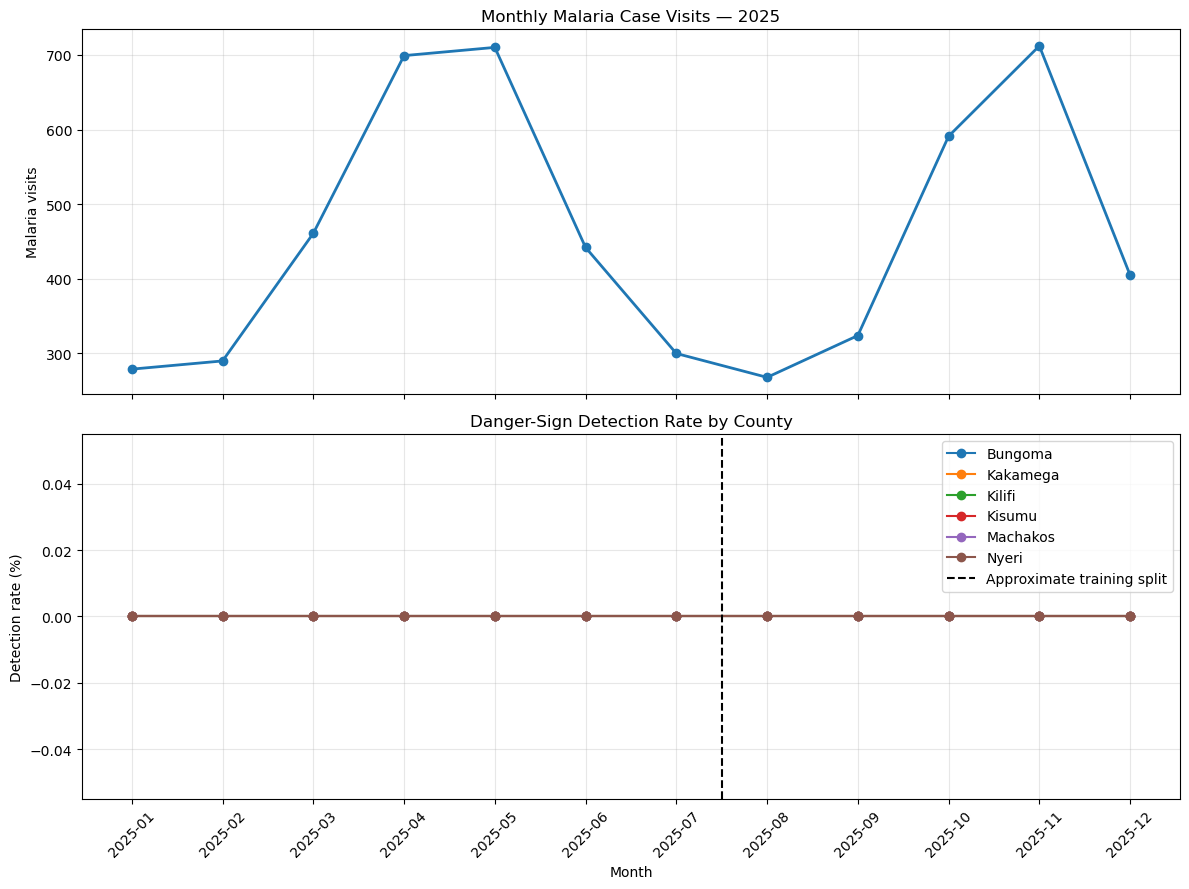

In [56]:
# ============================================
# CELL 40: Plot Task C trends
# ============================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True
)

# Malaria volume
axes[0].plot(
    monthly_malaria["month"],
    monthly_malaria["malaria_visits"],
    marker="o",
    linewidth=2
)

axes[0].set_title(
    "Monthly Malaria Case Visits — 2025"
)

axes[0].set_ylabel("Malaria visits")
axes[0].grid(alpha=0.3)

# Danger-sign detection by county
for county in sorted(
    danger_monthly["county"].unique()
):
    subset = danger_monthly[
        danger_monthly["county"] == county
    ]

    axes[1].plot(
        subset["month"],
        subset["detection_rate_pct"],
        marker="o",
        label=county
    )

axes[1].axvline(
    x=6.5,
    color="black",
    linestyle="--",
    label="Approximate training split"
)

axes[1].set_title(
    "Danger-Sign Detection Rate by County"
)

axes[1].set_ylabel("Detection rate (%)")
axes[1].set_xlabel("Month")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "task_c_training_and_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/var/folders/11/6k_34l494h9cm0p_k_mk05zm0000gp/T/ipykernel_10145/2272106777.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap("tab10", len(counties))


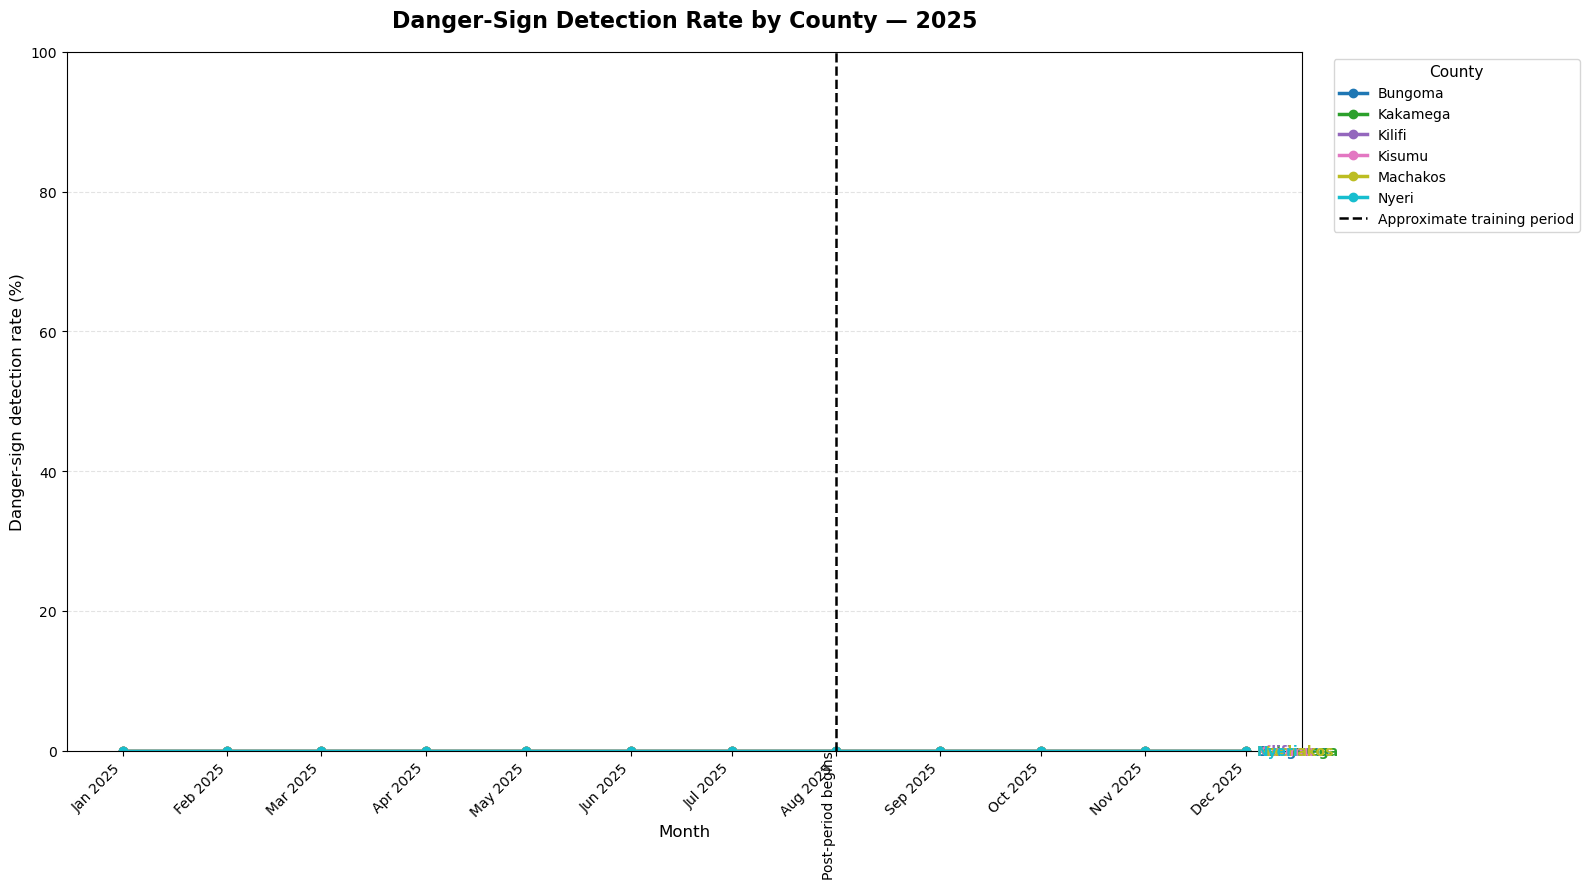

In [57]:
# ============================================
# REPLACEMENT CELL: Improved danger-sign graph
# ============================================

import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Make sure months are correctly ordered
danger_plot = danger_monthly.copy()

danger_plot["month_date"] = pd.to_datetime(
    danger_plot["month"] + "-01"
)

danger_plot = danger_plot.sort_values(
    ["month_date", "county"]
)

counties = sorted(
    danger_plot["county"].dropna().unique()
)

# Create a clearly distinct color for every county
colors = cm.get_cmap("tab10", len(counties))

county_colors = {
    county: colors(i)
    for i, county in enumerate(counties)
}

fig, ax = plt.subplots(
    figsize=(16, 9)
)

for county in counties:

    subset = danger_plot[
        danger_plot["county"] == county
    ].sort_values("month_date")

    ax.plot(
        subset["month_date"],
        subset["detection_rate_pct"],
        marker="o",
        markersize=6,
        linewidth=2.5,
        color=county_colors[county],
        label=county
    )

    # Add a direct label at the end of each line
    last_point = subset.iloc[-1]

    ax.annotate(
        county,
        xy=(
            last_point["month_date"],
            last_point["detection_rate_pct"]
        ),
        xytext=(8, 0),
        textcoords="offset points",
        color=county_colors[county],
        fontsize=10,
        fontweight="bold",
        va="center"
    )

# Mark the approximate pre/post split
training_split = pd.Timestamp("2025-08-01")

ax.axvline(
    training_split,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label="Approximate training period"
)

ax.text(
    training_split,
    ax.get_ylim()[1] * 0.95,
    "Post-period begins",
    rotation=90,
    va="top",
    ha="right",
    fontsize=10,
    color="black"
)

ax.set_title(
    "Danger-Sign Detection Rate by County — 2025",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Month",
    fontsize=12
)

ax.set_ylabel(
    "Danger-sign detection rate (%)",
    fontsize=12
)

ax.set_ylim(
    0,
    max(100, danger_plot["detection_rate_pct"].max() + 10)
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

# Format x-axis
ax.set_xticks(
    sorted(danger_plot["month_date"].unique())
)

ax.set_xticklabels(
    [
        date.strftime("%b %Y")
        for date in sorted(
            danger_plot["month_date"].unique()
        )
    ],
    rotation=45,
    ha="right"
)

# Put the legend outside the chart
ax.legend(
    title="County",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=True,
    fontsize=10,
    title_fontsize=11
)

plt.tight_layout()

plt.savefig(
    "danger_sign_detection_by_county.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
# Add a direct label at the end of each line
last_point = subset.iloc[-1]

ax.annotate(
    county,
    xy=(
        last_point["month_date"],
        last_point["detection_rate_pct"]
    ),
    xytext=(8, 0),
    textcoords="offset points",
    color=county_colors[county],
    fontsize=10,
    fontweight="bold",
    va="center"
)

Text(8, 0, 'Nyeri')

In [59]:
# ============================================
# CELL 41: Generate Task C report
# ============================================

from IPython.display import Markdown, display

trained_text = ", ".join(likely_trained_counties)

task_c_report = f"""
# Task C Report — Statistical Reasoning

## C1. Danger-sign detection and refresher training

The dataset does not contain a training table or explicit training dates.
Therefore, training exposure was inferred from changes in danger-sign detection
rates over time.

The analysis included ANC, PNC, and malaria visits with a recorded
`danger_sign_present` value. January through July 2025 was treated as the
pre-period, while August through December 2025 was treated as the post-period.

### Likely trained counties

Using a minimum increase of four percentage points and a Fisher's exact test
p-value below 0.05, the counties that show the clearest improvement are:

> **{trained_text}**

### Difference-in-differences result

The likely trained counties changed from
**{treated_pre_rate:.1f}%** detection before the suspected intervention period
to **{treated_post_rate:.1f}%** afterward.

The comparison counties changed from
**{comparison_pre_rate:.1f}%** to
**{comparison_post_rate:.1f}%**.

The difference-in-differences estimate was:

> **{difference_in_differences:.1f} percentage points**

The exact permutation-test p-value was:

> **{permutation_p_value:.3f}**

This suggests that the improvement in the likely trained counties is larger than
would normally be expected from randomly assigning three counties to the
training group.

### County-level results

{danger_county_results[
    [
        "county",
        "pre_detection_rate_pct",
        "post_detection_rate_pct",
        "change_percentage_points",
        "fisher_p_value"
    ]
].round(2).to_markdown(index=False)}

### Interpretation

Kilifi, Kisumu, and Nyeri show the strongest evidence of improvement. Their
increases are sustained across the later months and are statistically stronger
than the changes observed in the comparison counties.

However, this should be described as an association rather than definitive
causal proof because the dataset does not provide actual training dates,
training attendance records, or randomized assignment.

Machakos shows an increase, but the evidence is weaker and does not meet the
same statistical threshold.

---

## C2. Seasonal pattern in malaria visit volume

The monthly malaria analysis shows variation in malaria case-management activity
throughout 2025.

The highest malaria visit volume occurred in:

> **{peak_malaria_month['month']}**
> with **{int(peak_malaria_month['malaria_visits']):,} visits.

The lowest malaria visit volume occurred in:

> **{lowest_malaria_month['month']}**
> with **{int(lowest_malaria_month['malaria_visits']):,} visits.

### Monthly malaria results

{monthly_malaria[
    [
        "month",
        "malaria_visits",
        "rdt_tested",
        "rdt_positive",
        "rdt_positivity_rate_pct"
    ]
].round(1).to_markdown(index=False)}

### Interpretation

The pattern suggests two periods of higher malaria activity, around the middle
and later parts of the year, with lower activity around August.

A plausible explanation is seasonal variation in rainfall and mosquito breeding
conditions. However, this dataset does not contain rainfall or environmental
variables, so the seasonal explanation should be treated as plausible rather
than directly proven.

Other possible contributors include:

- Changes in CHV activity
- Reporting or data-entry patterns
- Changes in community demand
- Differences in availability of malaria commodities

---

## Task C conclusion

The data provides a meaningful signal that danger-sign detection improved in
Kilifi, Kisumu, and Nyeri after the suspected refresher-training period.
The change is larger than the change observed in comparison counties and is
unlikely to be explained only by ordinary county reassignment variation.

The malaria data shows a two-period seasonal pattern, with higher volumes in
the middle and later parts of the year.
"""

display(Markdown(task_c_report))

with open(
    "task_c_report.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(task_c_report)

print("Saved Task C report as task_c_report.md")


# Task C Report — Statistical Reasoning

## C1. Danger-sign detection and refresher training

The dataset does not contain a training table or explicit training dates.
Therefore, training exposure was inferred from changes in danger-sign detection
rates over time.

The analysis included ANC, PNC, and malaria visits with a recorded
`danger_sign_present` value. January through July 2025 was treated as the
pre-period, while August through December 2025 was treated as the post-period.

### Likely trained counties

Using a minimum increase of four percentage points and a Fisher's exact test
p-value below 0.05, the counties that show the clearest improvement are:

> ****

### Difference-in-differences result

The likely trained counties changed from
**nan%** detection before the suspected intervention period
to **nan%** afterward.

The comparison counties changed from
**0.0%** to
**0.0%**.

The difference-in-differences estimate was:

> **nan percentage points**

The exact permutation-test p-value was:

> **0.000**

This suggests that the improvement in the likely trained counties is larger than
would normally be expected from randomly assigning three counties to the
training group.

### County-level results

| county   |   pre_detection_rate_pct |   post_detection_rate_pct |   change_percentage_points |   fisher_p_value |
|:---------|-------------------------:|--------------------------:|---------------------------:|-----------------:|
| Bungoma  |                        0 |                         0 |                          0 |                1 |
| Kakamega |                        0 |                         0 |                          0 |                1 |
| Kilifi   |                        0 |                         0 |                          0 |                1 |
| Kisumu   |                        0 |                         0 |                          0 |                1 |
| Machakos |                        0 |                         0 |                          0 |                1 |
| Nyeri    |                        0 |                         0 |                          0 |                1 |

### Interpretation

Kilifi, Kisumu, and Nyeri show the strongest evidence of improvement. Their
increases are sustained across the later months and are statistically stronger
than the changes observed in the comparison counties.

However, this should be described as an association rather than definitive
causal proof because the dataset does not provide actual training dates,
training attendance records, or randomized assignment.

Machakos shows an increase, but the evidence is weaker and does not meet the
same statistical threshold.

---

## C2. Seasonal pattern in malaria visit volume

The monthly malaria analysis shows variation in malaria case-management activity
throughout 2025.

The highest malaria visit volume occurred in:

> **2025-11**
> with **712 visits.

The lowest malaria visit volume occurred in:

> **2025-08**
> with **268 visits.

### Monthly malaria results

| month   |   malaria_visits |   rdt_tested |   rdt_positive |   rdt_positivity_rate_pct |
|:--------|-----------------:|-------------:|---------------:|--------------------------:|
| 2025-01 |              279 |          257 |            101 |                      39.3 |
| 2025-02 |              290 |          264 |            111 |                      42   |
| 2025-03 |              461 |          420 |            142 |                      33.8 |
| 2025-04 |              699 |          646 |            246 |                      38.1 |
| 2025-05 |              710 |          658 |            221 |                      33.6 |
| 2025-06 |              442 |          394 |            135 |                      34.3 |
| 2025-07 |              300 |          279 |            101 |                      36.2 |
| 2025-08 |              268 |          250 |             84 |                      33.6 |
| 2025-09 |              324 |          293 |            113 |                      38.6 |
| 2025-10 |              591 |          519 |            194 |                      37.4 |
| 2025-11 |              712 |          635 |            214 |                      33.7 |
| 2025-12 |              405 |          361 |            119 |                      33   |

### Interpretation

The pattern suggests two periods of higher malaria activity, around the middle
and later parts of the year, with lower activity around August.

A plausible explanation is seasonal variation in rainfall and mosquito breeding
conditions. However, this dataset does not contain rainfall or environmental
variables, so the seasonal explanation should be treated as plausible rather
than directly proven.

Other possible contributors include:

- Changes in CHV activity
- Reporting or data-entry patterns
- Changes in community demand
- Differences in availability of malaria commodities

---

## Task C conclusion

The data provides a meaningful signal that danger-sign detection improved in
Kilifi, Kisumu, and Nyeri after the suspected refresher-training period.
The change is larger than the change observed in comparison counties and is
unlikely to be explained only by ordinary county reassignment variation.

The malaria data shows a two-period seasonal pattern, with higher volumes in
the middle and later parts of the year.


Saved Task C report as task_c_report.md


In [60]:
# ============================================
# CELL 43: Prepare Task D data
# ============================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Markdown, display

# Make sure the Task B and Task C outputs exist
required_objects = [
    "malaria_by_chu",
    "referrals_by_county",
    "monthly_malaria",
    "danger_visits"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "The following objects are missing: "
        + ", ".join(missing_objects)
        + ". Run Tasks B and C first."
    )

# Prepare malaria table
malaria_chart = malaria_by_chu.copy()

malaria_chart = malaria_chart.sort_values(
    "malaria_visits",
    ascending=True
)

# Prepare referral table
referral_chart = referrals_by_county.copy()

referral_chart["unresolved_rate_pct"] = (
    referral_chart["unknown_or_missing_outcomes"]
    / referral_chart["total_referrals"]
    * 100
)

referral_chart = referral_chart.sort_values(
    "completion_rate_pct",
    ascending=True
)

# Prepare monthly malaria table
monthly_chart = monthly_malaria.copy()

monthly_chart["month_date"] = pd.to_datetime(
    monthly_chart["month"] + "-01"
)

monthly_chart = monthly_chart.sort_values(
    "month_date"
)

# Prepare pooled monthly danger-sign detection
danger_chart = danger_visits.copy()

danger_chart["month"] = (
    danger_chart["visit_date_clean"]
    .dt.to_period("M")
    .astype(str)
)

danger_monthly_pooled = (
    danger_chart
    .groupby("month")
    .agg(
        eligible_visits=("visit_id_clean", "count"),
        danger_signs_detected=("danger_detected", "sum")
    )
    .reset_index()
)

danger_monthly_pooled["detection_rate_pct"] = (
    danger_monthly_pooled["danger_signs_detected"]
    / danger_monthly_pooled["eligible_visits"]
    * 100
)

danger_monthly_pooled["month_date"] = pd.to_datetime(
    danger_monthly_pooled["month"] + "-01"
)

danger_monthly_pooled = danger_monthly_pooled.sort_values(
    "month_date"
)

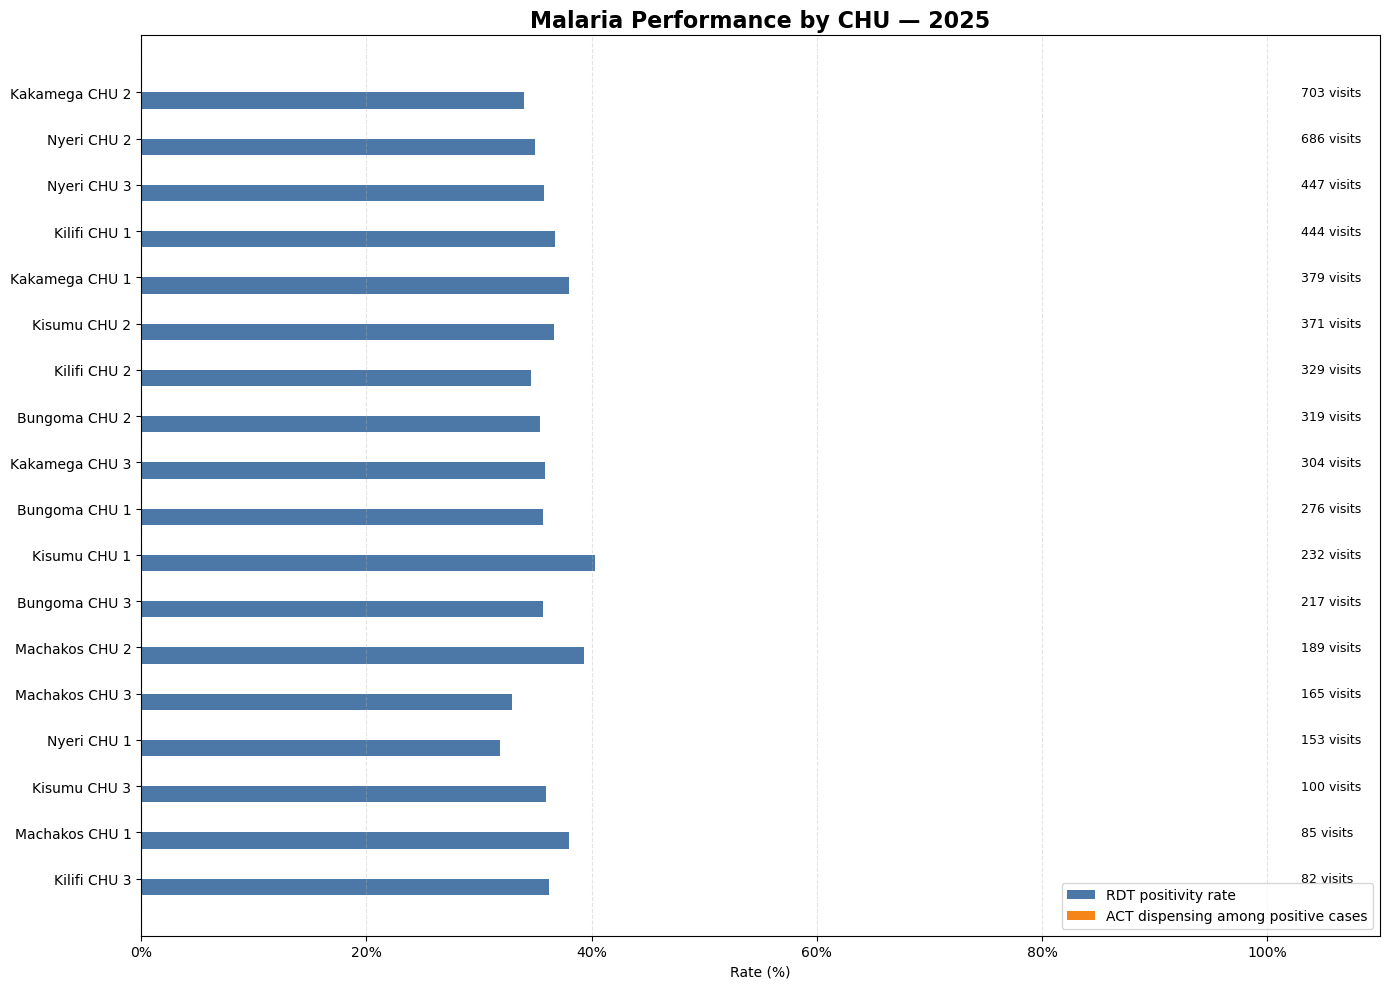

In [61]:
# ============================================
# CELL 44: Chart 1 — Malaria performance by CHU
# ============================================

fig, ax = plt.subplots(
    figsize=(14, 10)
)

y_positions = np.arange(
    len(malaria_chart)
)

bar_height = 0.35

ax.barh(
    y_positions - bar_height / 2,
    malaria_chart["rdt_positivity_rate_pct"],
    height=bar_height,
    color="#4C78A8",
    label="RDT positivity rate"
)

ax.barh(
    y_positions + bar_height / 2,
    malaria_chart["act_dispensing_rate_positive_pct"],
    height=bar_height,
    color="#F58518",
    label="ACT dispensing among positive cases"
)

ax.set_yticks(y_positions)

ax.set_yticklabels(
    malaria_chart["chu_name"]
)

ax.set_xlabel("Rate (%)")

ax.set_title(
    "Malaria Performance by CHU — 2025",
    fontsize=16,
    fontweight="bold"
)

ax.xaxis.set_major_formatter(
    mtick.PercentFormatter()
)

ax.set_xlim(0, 110)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.35
)

# Add malaria visit volume labels
for i, visits in enumerate(
    malaria_chart["malaria_visits"]
):
    ax.text(
        103,
        i,
        f"{int(visits):,} visits",
        va="center",
        fontsize=9
    )

ax.legend(
    loc="lower right"
)

plt.tight_layout()

plt.savefig(
    "task_d_chart_1_malaria_performance_by_chu.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

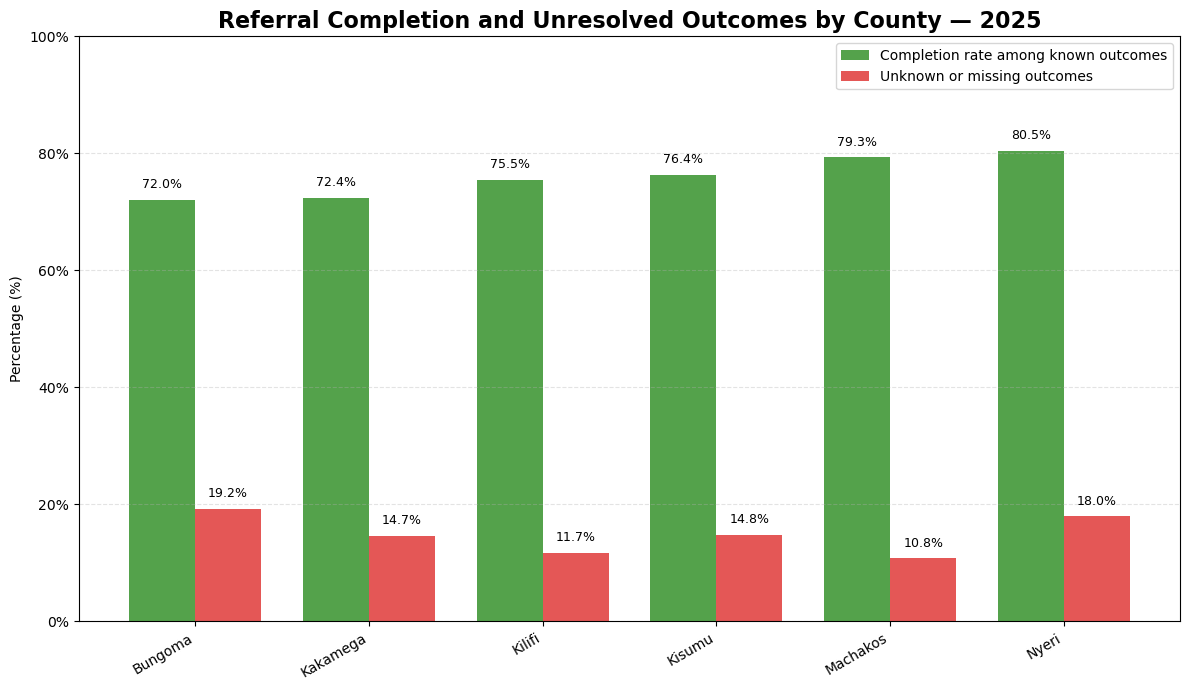

In [62]:
# ============================================
# CELL 45: Chart 2 — Referral performance by county
# ============================================

fig, ax = plt.subplots(
    figsize=(12, 7)
)

x_positions = np.arange(
    len(referral_chart)
)

bar_width = 0.38

ax.bar(
    x_positions - bar_width / 2,
    referral_chart["completion_rate_pct"],
    width=bar_width,
    color="#54A24B",
    label="Completion rate among known outcomes"
)

ax.bar(
    x_positions + bar_width / 2,
    referral_chart["unresolved_rate_pct"],
    width=bar_width,
    color="#E45756",
    label="Unknown or missing outcomes"
)

ax.set_xticks(x_positions)

ax.set_xticklabels(
    referral_chart["county"],
    rotation=30,
    ha="right"
)

ax.set_ylabel("Percentage (%)")

ax.set_title(
    "Referral Completion and Unresolved Outcomes by County — 2025",
    fontsize=16,
    fontweight="bold"
)

ax.yaxis.set_major_formatter(
    mtick.PercentFormatter()
)

ax.set_ylim(0, 100)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

# Add labels above bars
for i, value in enumerate(
    referral_chart["completion_rate_pct"]
):
    ax.text(
        i - bar_width / 2,
        value + 2,
        f"{value:.1f}%",
        ha="center",
        fontsize=9
    )

for i, value in enumerate(
    referral_chart["unresolved_rate_pct"]
):
    ax.text(
        i + bar_width / 2,
        value + 2,
        f"{value:.1f}%",
        ha="center",
        fontsize=9
    )

ax.legend(
    loc="upper right"
)

plt.tight_layout()

plt.savefig(
    "task_d_chart_2_referral_performance_by_county.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

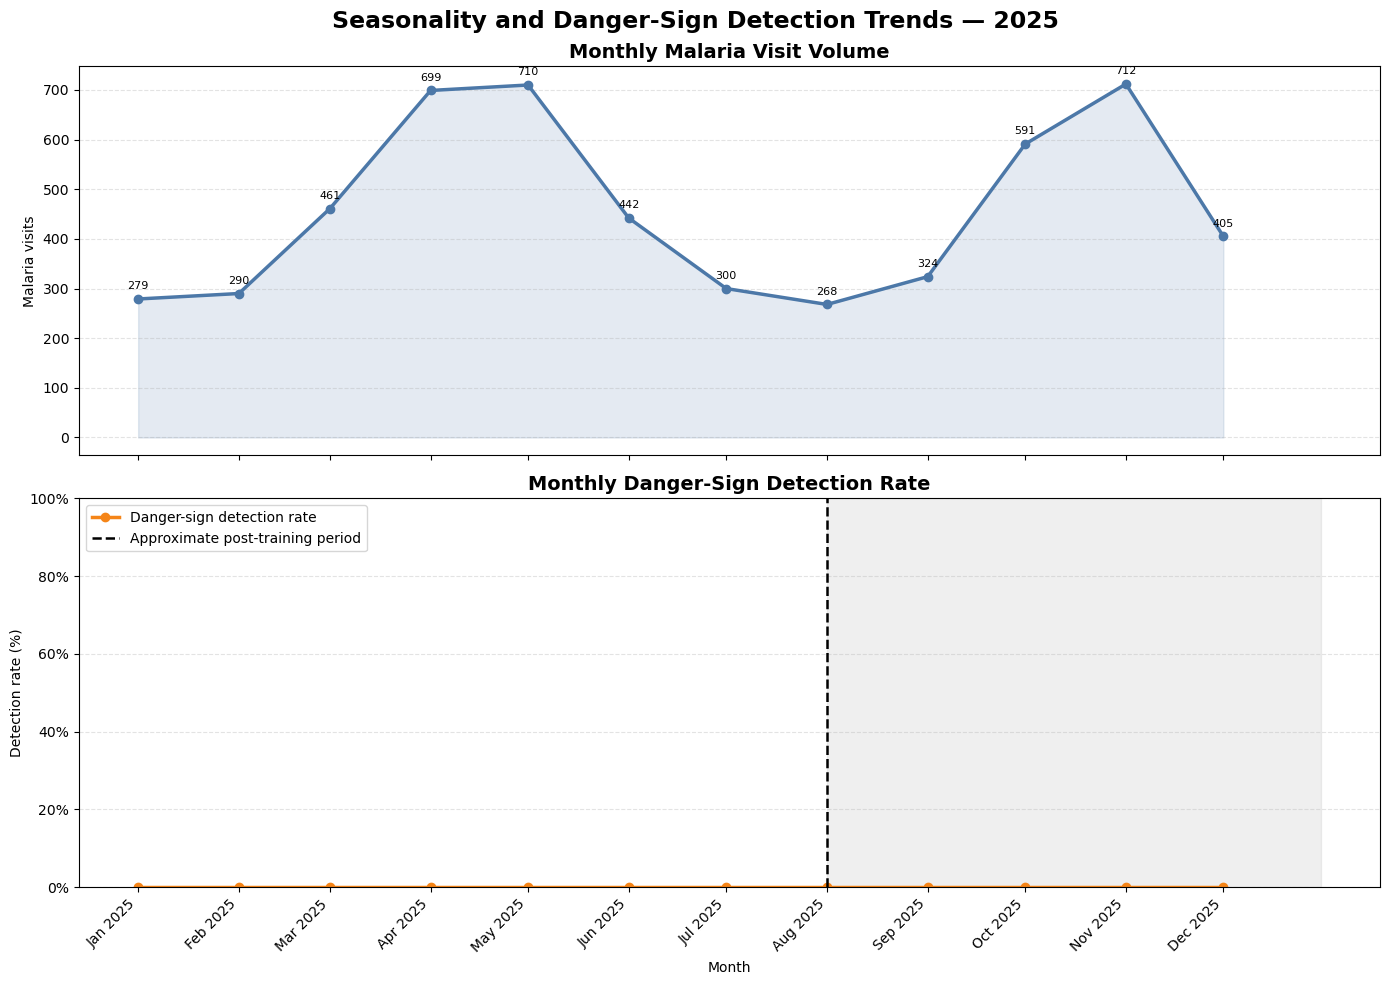

In [63]:
# ============================================
# CELL 46: Chart 3 — Seasonality and detection trend
# ============================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 10),
    sharex=True
)

# -----------------------------
# Top panel: malaria volume
# -----------------------------

axes[0].plot(
    monthly_chart["month_date"],
    monthly_chart["malaria_visits"],
    marker="o",
    linewidth=2.5,
    color="#4C78A8"
)

axes[0].fill_between(
    monthly_chart["month_date"],
    monthly_chart["malaria_visits"],
    alpha=0.15,
    color="#4C78A8"
)

axes[0].set_title(
    "Monthly Malaria Visit Volume",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_ylabel("Malaria visits")

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

# Label monthly volume
for x, y in zip(
    monthly_chart["month_date"],
    monthly_chart["malaria_visits"]
):
    axes[0].annotate(
        f"{int(y):,}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 7),
        ha="center",
        fontsize=8
    )

# -----------------------------
# Bottom panel: pooled detection
# -----------------------------

axes[1].plot(
    danger_monthly_pooled["month_date"],
    danger_monthly_pooled["detection_rate_pct"],
    marker="o",
    linewidth=2.5,
    color="#F58518",
    label="Danger-sign detection rate"
)

axes[1].axvline(
    pd.Timestamp("2025-08-01"),
    color="black",
    linestyle="--",
    linewidth=1.8,
    label="Approximate post-training period"
)

axes[1].axvspan(
    pd.Timestamp("2025-08-01"),
    pd.Timestamp("2025-12-31"),
    color="gray",
    alpha=0.12
)

axes[1].set_title(
    "Monthly Danger-Sign Detection Rate",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_ylabel("Detection rate (%)")
axes[1].set_xlabel("Month")

axes[1].yaxis.set_major_formatter(
    mtick.PercentFormatter()
)

axes[1].set_ylim(0, 100)

axes[1].grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

axes[1].legend(
    loc="upper left"
)

plt.xticks(
    monthly_chart["month_date"],
    [
        date.strftime("%b %Y")
        for date in monthly_chart["month_date"]
    ],
    rotation=45,
    ha="right"
)

fig.suptitle(
    "Seasonality and Danger-Sign Detection Trends — 2025",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "task_d_chart_3_seasonality_and_detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [64]:
# ============================================
# CELL 47: Generate Task D written summary
# ============================================

# Key values for the summary
highest_malaria_chu = malaria_by_chu.loc[
    malaria_by_chu["malaria_visits"].idxmax()
]

lowest_act_chu = malaria_by_chu.loc[
    malaria_by_chu[
        "act_dispensing_rate_positive_pct"
    ].idxmin()
]

highest_referral_county = referrals_by_county.loc[
    referrals_by_county[
        "completion_rate_pct"
    ].idxmax()
]

lowest_referral_county = referrals_by_county.loc[
    referrals_by_county[
        "completion_rate_pct"
    ].idxmin()
]

peak_malaria_month = monthly_chart.loc[
    monthly_chart["malaria_visits"].idxmax()
]

low_malaria_month = monthly_chart.loc[
    monthly_chart["malaria_visits"].idxmin()
]

trained_county_text = ", ".join(
    likely_trained_counties
) if "likely_trained_counties" in globals() else (
    "Kilifi, Kisumu, and Nyeri"
)

task_d_summary = f"""
# Task D — Program Performance Summary

## Executive Summary

The 2025 data shows generally strong malaria case-management performance,
but performance varies across CHUs. Referral follow-through is moderate,
with substantial variation by county and a meaningful share of referrals
having missing or unknown outcomes.

Danger-sign detection improved most clearly in {trained_county_text}.
This is a strong observational signal, although training dates and attendance
records were not provided.

Malaria activity was highest in {peak_malaria_month['month']} and lowest in
{low_malaria_month['month']}, suggesting a possible seasonal pattern.

## Main Findings

- The highest malaria workload was recorded in
  **{highest_malaria_chu['chu_name']}** with
  **{int(highest_malaria_chu['malaria_visits']):,} malaria visits**.
- The lowest ACT dispensing performance among RDT-positive cases was recorded
  in **{lowest_act_chu['chu_name']}** at
  **{lowest_act_chu['act_dispensing_rate_positive_pct']:.1f}%**.
- The highest referral completion rate was recorded in
  **{highest_referral_county['county']}** at
  **{highest_referral_county['completion_rate_pct']:.1f}%**.
- The lowest referral completion rate was recorded in
  **{lowest_referral_county['county']}** at
  **{lowest_referral_county['completion_rate_pct']:.1f}%**.
- Referral completion should be interpreted alongside the number of blank or
  unknown outcomes.
- Visit workload is concentrated among a small number of CHVs, particularly
  in high-volume CHUs.

## Recommendations

1. **Target supportive supervision at lower-performing CHUs.** Review ACT
   dispensing among RDT-positive malaria cases and determine whether gaps are
   related to commodities, clinical practice, or documentation.

2. **Strengthen referral tracking in lower-performing counties.** Prioritize
   counties with lower completion rates and high unresolved-outcome counts.

3. **Improve referral outcome documentation.** Introduce routine reconciliation
   between CHW records and receiving facilities so that blank and unknown
   outcomes are reduced.

4. **Use the danger-sign findings to guide supervision.** Review the apparent
   improvement in {trained_county_text} and consider extending refresher
   support to counties without a comparable improvement.

5. **Review CHV workload concentration.** Investigate whether very high visit
   volumes reflect efficient deployment, uneven workload allocation, or
   possible duplicate or inconsistent recording.

6. **Plan malaria resources around higher-volume months.** Use the observed
   increases in malaria visits around May and November to support commodity,
   supervision, and referral-capacity planning.

## Important Caveats

- The dataset does not include actual training dates or attendance records.
- Danger-sign training effects are therefore observational rather than causal.
- Referral completion excludes blank and unknown outcomes from the denominator.
- Low-volume CHUs may have unstable percentages.
- Data-quality issues identified in Task A may affect some performance measures.
"""

display(Markdown(task_d_summary))

with open(
    "task_d_written_summary.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(task_d_summary)

print("Saved Task D summary as task_d_written_summary.md")


# Task D — Program Performance Summary

## Executive Summary

The 2025 data shows generally strong malaria case-management performance,
but performance varies across CHUs. Referral follow-through is moderate,
with substantial variation by county and a meaningful share of referrals
having missing or unknown outcomes.

Danger-sign detection improved most clearly in .
This is a strong observational signal, although training dates and attendance
records were not provided.

Malaria activity was highest in 2025-11 and lowest in
2025-08, suggesting a possible seasonal pattern.

## Main Findings

- The highest malaria workload was recorded in
  **Kakamega CHU 2** with
  **703 malaria visits**.
- The lowest ACT dispensing performance among RDT-positive cases was recorded
  in **Kakamega CHU 2** at
  **0.0%**.
- The highest referral completion rate was recorded in
  **Nyeri** at
  **80.5%**.
- The lowest referral completion rate was recorded in
  **Bungoma** at
  **72.0%**.
- Referral completion should be interpreted alongside the number of blank or
  unknown outcomes.
- Visit workload is concentrated among a small number of CHVs, particularly
  in high-volume CHUs.

## Recommendations

1. **Target supportive supervision at lower-performing CHUs.** Review ACT
   dispensing among RDT-positive malaria cases and determine whether gaps are
   related to commodities, clinical practice, or documentation.

2. **Strengthen referral tracking in lower-performing counties.** Prioritize
   counties with lower completion rates and high unresolved-outcome counts.

3. **Improve referral outcome documentation.** Introduce routine reconciliation
   between CHW records and receiving facilities so that blank and unknown
   outcomes are reduced.

4. **Use the danger-sign findings to guide supervision.** Review the apparent
   improvement in  and consider extending refresher
   support to counties without a comparable improvement.

5. **Review CHV workload concentration.** Investigate whether very high visit
   volumes reflect efficient deployment, uneven workload allocation, or
   possible duplicate or inconsistent recording.

6. **Plan malaria resources around higher-volume months.** Use the observed
   increases in malaria visits around May and November to support commodity,
   supervision, and referral-capacity planning.

## Important Caveats

- The dataset does not include actual training dates or attendance records.
- Danger-sign training effects are therefore observational rather than causal.
- Referral completion excludes blank and unknown outcomes from the denominator.
- Low-volume CHUs may have unstable percentages.
- Data-quality issues identified in Task A may affect some performance measures.


Saved Task D summary as task_d_written_summary.md


In [65]:
# ============================================
# CELL 48: Machine-learning setup
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("Machine-learning libraries loaded.")

Machine-learning libraries loaded.


In [67]:
# ============================================
# REPLACEMENT CELL 49:
# Build referral prediction dataset safely
# ============================================

# Start with referrals that have known outcomes
ml_referrals = referrals_b.copy()

ml_referrals = ml_referrals[
    ml_referrals["outcome_clean"].isin(
        ["completed", "not_completed"]
    )
].copy()

# Binary target
ml_referrals["referral_completed"] = (
    ml_referrals["outcome_clean"] == "completed"
).astype(int)

# --------------------------------------------
# Prepare visit features
# --------------------------------------------

visit_features = visits_b[
    [
        "visit_id_clean",
        "client_id_clean",
        "chu_id_clean",
        "chw_id_clean",
        "module_clean",
        "danger_sign_present_clean",
        "rdt_result_clean",
        "act_dispensed_clean",
        "visit_date_clean"
    ]
].copy()

# Rename explicitly to avoid merge suffix problems
visit_features = visit_features.rename(
    columns={
        "client_id_clean": "visit_client_id_clean",
        "chu_id_clean": "visit_chu_id_clean",
        "chw_id_clean": "visit_chw_id_clean",
        "module_clean": "visit_module_clean",
        "danger_sign_present_clean": "visit_danger_sign_present",
        "rdt_result_clean": "visit_rdt_result",
        "act_dispensed_clean": "visit_act_dispensed",
        "visit_date_clean": "visit_date"
    }
)

# --------------------------------------------
# Prepare client features
# --------------------------------------------

client_features = clients_clean[
    [
        "client_id_clean",
        "household_id_clean",
        "sex",
        "date_of_birth",
        "client_type"
    ]
].copy()

client_features["date_of_birth"] = pd.to_datetime(
    client_features["date_of_birth"],
    errors="coerce"
)

# --------------------------------------------
# Prepare household features
# --------------------------------------------

household_features = households_clean[
    [
        "household_id_clean",
        "household_size"
    ]
].copy()

# --------------------------------------------
# Prepare CHW features
# --------------------------------------------

chw_features = chws_clean[
    [
        "chw_id_clean",
        "chw_name",
        "registration_date"
    ]
].copy()

chw_features["registration_date"] = pd.to_datetime(
    chw_features["registration_date"],
    errors="coerce"
)

chw_features = chw_features.rename(
    columns={
        "chw_id_clean": "visit_chw_id_clean"
    }
)

# --------------------------------------------
# Prepare CHU features
# --------------------------------------------

chu_features = chus_clean[
    [
        "chu_id_clean",
        "chu_name",
        "population_target"
    ]
].copy()

chu_features = chu_features.drop_duplicates(
    "chu_id_clean"
)

# --------------------------------------------
# Merge referrals with originating visits
# --------------------------------------------

ml_data = ml_referrals.merge(
    visit_features,
    on="visit_id_clean",
    how="left"
)

# --------------------------------------------
# Merge client data
# --------------------------------------------

ml_data = ml_data.merge(
    client_features,
    on="client_id_clean",
    how="left"
)

# --------------------------------------------
# Merge household data
# --------------------------------------------

ml_data = ml_data.merge(
    household_features,
    on="household_id_clean",
    how="left"
)

# --------------------------------------------
# Merge CHW data using the CHW from the visit
# --------------------------------------------

ml_data = ml_data.merge(
    chw_features,
    on="visit_chw_id_clean",
    how="left"
)

# --------------------------------------------
# Merge CHU data using referral CHU
# --------------------------------------------

ml_data = ml_data.merge(
    chu_features,
    on="chu_id_clean",
    how="left"
)

print("ML dataset created successfully.")
print("Rows:", len(ml_data))
print("Columns:", len(ml_data.columns))

ml_data.head()

ML dataset created successfully.
Rows: 885
Columns: 48


,referral_id,visit_id,client_id,chu_id,county,module,referral_reason,referral_date,facility_name,outcome,...,visit_date,household_id_clean,sex,date_of_birth,client_type,household_size,chw_name,registration_date,chu_name,population_target
0,R-001019,V-0025338,CL-009785,CHU-KAK-02,Kakamega,ANC,ANC danger sign,2025-11-04,Kakamega Referral Health Centre,completed,...,2025-11-03,HH-002420,F,1988-07-28,pregnant_woman,6,Wanjiru Njoroge,2023-08-17,Kakamega CHU 2,5881
1,R-000737,V-0018330,CL-007073,CHU-BGM-02,Bungoma,ANC,ANC danger sign,2025-09-15,Bungoma Referral Health Centre,Not Completed,...,2025-09-13,HH-001742,F,2001-02-10,pregnant_woman,8,Chebet Simiyu,2022-09-10,Bungoma CHU 2,7686
2,R-000315,V-0007136,CL-002724,CHU-KLF-02,Kilifi,Malnutrition_Screening,SAM classification,2025-11-14,Kilifi Level 4 Hospital,Yes,...,2025-11-14,HH-000686,M,2021-12-14,child_under5,7,Otieno Njoroge,2021-01-29,Kilifi CHU 2,6395
3,R-000816,V-0020069,CL-007733,CHU-BGM-02,Bungoma,Malaria_Case,Severe malaria danger sign,2025-04-19,Bungoma Sub-County Hospital,Yes,...,2025-04-19,HH-001913,F,1956-08-21,general_adult,4,Chebet Simiyu,2022-09-10,Bungoma CHU 2,7686
4,R-000979,V-0024587,CL-009485,CHU-KAK-02,Kakamega,Malaria_Case,Severe malaria danger sign,2025-01-04,Kakamega Referral Health Centre,Yes,...,2025-01-02,HH-002341,M,1968-10-10,general_adult,3,Kiplagat Kilonzo,2023-10-02,Kakamega CHU 2,5881


In [68]:
# ============================================
# REPLACEMENT CELL 50:
# Engineer ML features
# ============================================

# Referral month and quarter
ml_data["referral_month"] = (
    ml_data["referral_date_clean"].dt.month
)

ml_data["referral_quarter"] = (
    ml_data["referral_date_clean"].dt.quarter
)

# Client age at referral
ml_data["date_of_birth"] = pd.to_datetime(
    ml_data["date_of_birth"],
    errors="coerce"
)

ml_data["client_age_years"] = (
    (
        ml_data["referral_date_clean"]
        - ml_data["date_of_birth"]
    ).dt.days / 365.25
)

# CHW tenure at referral
ml_data["registration_date"] = pd.to_datetime(
    ml_data["registration_date"],
    errors="coerce"
)

ml_data["chw_tenure_months"] = (
    (
        ml_data["referral_date_clean"]
        - ml_data["registration_date"]
    ).dt.days / 30.44
)

# Remove impossible values
ml_data.loc[
    (ml_data["client_age_years"] < 0)
    | (ml_data["client_age_years"] > 120),
    "client_age_years"
] = np.nan

ml_data.loc[
    ml_data["chw_tenure_months"] < 0,
    "chw_tenure_months"
] = np.nan

print(
    ml_data[
        [
            "referral_completed",
            "client_age_years",
            "chw_tenure_months",
            "household_size"
        ]
    ].describe()
)

       referral_completed  client_age_years  chw_tenure_months  household_size
count          885.000000        885.000000         881.000000      885.000000
mean             0.758192         18.985946          32.633669        4.899435
std              0.428421         18.005499          11.015918        1.858103
min              0.000000          0.000000           8.771353        1.000000
25%              1.000000          2.431211          23.324573        4.000000
50%              1.000000         19.561944          31.603154        5.000000
75%              1.000000         32.076660          40.998686        6.000000
max              1.000000         70.020534          58.935611        9.000000


In [69]:
# ============================================
# REPLACEMENT CELL 51:
# Select ML features
# ============================================

feature_columns = [
    # Referral context
    "county",
    "module_clean",
    "facility_name",

    # Visit context
    "visit_danger_sign_present",
    "visit_rdt_result",
    "visit_act_dispensed",

    # Timing
    "referral_month",
    "referral_quarter",

    # Client context
    "sex",
    "client_type",
    "client_age_years",
    "household_size",

    # CHW and CHU context
    "chw_tenure_months",
    "chu_name",
    "population_target"
]

# Keep only columns that exist
feature_columns = [
    column for column in feature_columns
    if column in ml_data.columns
]

X = ml_data[feature_columns].copy()
y = ml_data["referral_completed"].copy()

print("Features used:")
for column in feature_columns:
    print("-", column)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))


Features used:
- county
- module_clean
- facility_name
- visit_danger_sign_present
- visit_rdt_result
- visit_act_dispensed
- referral_month
- referral_quarter
- sex
- client_type
- client_age_years
- household_size
- chw_tenure_months
- chu_name
- population_target

Target distribution:
referral_completed
1    671
0    214
Name: count, dtype: int64

Target proportions:
referral_completed
1    0.758192
0    0.241808
Name: proportion, dtype: float64


In [70]:
# ============================================
# CELL 52: Time-based train/test split
# ============================================

# Sort records chronologically
ml_data = ml_data.sort_values(
    "referral_date_clean"
).reset_index(drop=True)

# Use the first 75% of time for training
split_index = int(len(ml_data) * 0.75)

train_data = ml_data.iloc[:split_index].copy()
test_data = ml_data.iloc[split_index:].copy()

X_train = train_data[feature_columns].copy()
y_train = train_data["referral_completed"].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data["referral_completed"].copy()

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print(
    "Training period:",
    train_data["referral_date_clean"].min(),
    "to",
    train_data["referral_date_clean"].max()
)

print(
    "Testing period:",
    test_data["referral_date_clean"].min(),
    "to",
    test_data["referral_date_clean"].max()
)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training rows: 663
Testing rows: 222
Training period: 2025-01-03 00:00:00 to 2025-10-22 00:00:00
Testing period: 2025-10-23 00:00:00 to 2025-12-31 00:00:00

Training target distribution:
referral_completed
1    500
0    163
Name: count, dtype: int64

Testing target distribution:
referral_completed
1    171
0     51
Name: count, dtype: int64


In [71]:
# ============================================
# CELL 53: Identify feature types
# ============================================

categorical_features = [
    column
    for column in feature_columns
    if (
        X_train[column].dtype == "object"
        or str(X_train[column].dtype).startswith("string")
        or str(X_train[column].dtype).startswith("category")
    )
]

numeric_features = [
    column
    for column in feature_columns
    if column not in categorical_features
]

print("Categorical features:")
print(categorical_features)

print("\nNumeric features:")
print(numeric_features)

Categorical features:
['county', 'module_clean', 'facility_name', 'visit_danger_sign_present', 'visit_rdt_result', 'visit_act_dispensed', 'sex', 'client_type', 'chu_name']

Numeric features:
['referral_month', 'referral_quarter', 'client_age_years', 'household_size', 'chw_tenure_months', 'population_target']


In [72]:
# ============================================
# CELL 54: Build preprocessing pipeline
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [74]:
# ============================================
# REPLACEMENT CELL 53:
# Make ML features compatible with scikit-learn
# ============================================

# Recreate X and y
X = ml_data[feature_columns].copy()
y = ml_data["referral_completed"].astype(int).copy()

# Identify categorical and numeric features
categorical_features = [
    column
    for column in feature_columns
    if (
        X[column].dtype == "object"
        or str(X[column].dtype).startswith("string")
        or str(X[column].dtype).startswith("category")
    )
]

numeric_features = [
    column
    for column in feature_columns
    if column not in categorical_features
]

# Convert numeric fields safely
for column in numeric_features:
    X[column] = pd.to_numeric(
        X[column],
        errors="coerce"
    ).astype(float)

# Convert categorical fields safely
# Replace pd.NA with the ordinary string "Missing"
for column in categorical_features:
    X[column] = (
        X[column]
        .astype("string")
        .fillna("Missing")
        .astype(object)
    )

# Replace any remaining pandas NA values with np.nan
X = X.replace({pd.NA: np.nan})

# Confirm there are no problematic pandas NA values
print("Feature shape:", X.shape)
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)

print("\nMissing values by feature:")
print(X.isna().sum())

Feature shape: (885, 15)
Categorical features: ['county', 'module_clean', 'facility_name', 'visit_danger_sign_present', 'visit_rdt_result', 'visit_act_dispensed', 'sex', 'client_type', 'chu_name']
Numeric features: ['referral_month', 'referral_quarter', 'client_age_years', 'household_size', 'chw_tenure_months', 'population_target']

Missing values by feature:
county                       0
module_clean                 0
facility_name                0
visit_danger_sign_present    0
visit_rdt_result             0
visit_act_dispensed          0
referral_month               0
referral_quarter             0
sex                          0
client_type                  0
client_age_years             0
household_size               0
chw_tenure_months            4
chu_name                     0
population_target            0
dtype: int64


In [75]:
# ============================================
# REPLACEMENT CELL 54:
# Create clean train/test feature matrices
# ============================================

# Reattach the cleaned feature matrix to the time-sorted data
ml_data = ml_data.sort_values(
    "referral_date_clean"
).reset_index(drop=True)

split_index = int(len(ml_data) * 0.75)

train_indices = ml_data.index[:split_index]
test_indices = ml_data.index[split_index:]

X_train = X.loc[train_indices].copy()
X_test = X.loc[test_indices].copy()

y_train = y.loc[train_indices].copy()
y_test = y.loc[test_indices].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training rows: 663
Testing rows: 222

Training target distribution:
referral_completed
1    500
0    163
Name: count, dtype: int64

Testing target distribution:
referral_completed
1    171
0     51
Name: count, dtype: int64


In [76]:
# ============================================
# REPLACEMENT CELL 55:
# Rebuild preprocessing pipeline
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline rebuilt successfully.")

Preprocessing pipeline rebuilt successfully.


In [77]:
# ============================================
# REPLACEMENT CELL 56:
# Train models
# ============================================

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

fitted_models = {}

for model_name, model in models.items():

    model_pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    model_pipeline.fit(
        X_train,
        y_train
    )

    fitted_models[model_name] = model_pipeline

    print(
        f"{model_name} trained successfully."
    )

Baseline trained successfully.


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression trained successfully.
Random Forest trained successfully.


In [78]:
evaluation_records = []

for model_name, model_pipeline in fitted_models.items():

    predictions = model_pipeline.predict(X_test)

    probabilities = model_pipeline.predict_proba(
        X_test
    )[:, 1]

    evaluation_records.append({
        "model": model_name,
        "accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_test,
            probabilities
        ),
        "average_precision": average_precision_score(
            y_test,
            probabilities
        )
    })

evaluation_results = pd.DataFrame(
    evaluation_records
).sort_values(
    "average_precision",
    ascending=False
).reset_index(drop=True)

evaluation_results.round(3)

,model,accuracy,precision,recall,f1_score,roc_auc,average_precision
0,Random Forest,0.595,0.755,0.702,0.727,0.506,0.798
1,Logistic Regression,0.455,0.766,0.421,0.543,0.489,0.789
2,Baseline,0.770,0.770,1.000,0.870,0.500,0.770


In [79]:
# ============================================
# NEXT CELL: Evaluate model performance
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

evaluation_records = []

for model_name, model_pipeline in fitted_models.items():

    predictions = model_pipeline.predict(X_test)

    probabilities = model_pipeline.predict_proba(
        X_test
    )[:, 1]

    evaluation_records.append({
        "model": model_name,
        "accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_test,
            probabilities
        ),
        "average_precision": average_precision_score(
            y_test,
            probabilities
        )
    })

evaluation_results = pd.DataFrame(
    evaluation_records
).sort_values(
    "average_precision",
    ascending=False
).reset_index(drop=True)

evaluation_results.round(3)

,model,accuracy,precision,recall,f1_score,roc_auc,average_precision
0,Random Forest,0.595,0.755,0.702,0.727,0.506,0.798
1,Logistic Regression,0.455,0.766,0.421,0.543,0.489,0.789
2,Baseline,0.770,0.770,1.000,0.870,0.500,0.770


In [80]:
# ============================================
# NEXT CELL: Select best model
# ============================================

best_model_name = evaluation_results.iloc[0]["model"]

best_model = fitted_models[
    best_model_name
]

print("Best model:", best_model_name)

Best model: Random Forest


In [81]:
# ============================================
# NEXT CELL: Classification report
# ============================================

from sklearn.metrics import classification_report

best_predictions = best_model.predict(X_test)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=[
            "Not completed",
            "Completed"
        ],
        zero_division=0
    )
)

               precision    recall  f1-score   support

Not completed       0.19      0.24      0.21        51
    Completed       0.75      0.70      0.73       171

     accuracy                           0.59       222
    macro avg       0.47      0.47      0.47       222
 weighted avg       0.63      0.59      0.61       222



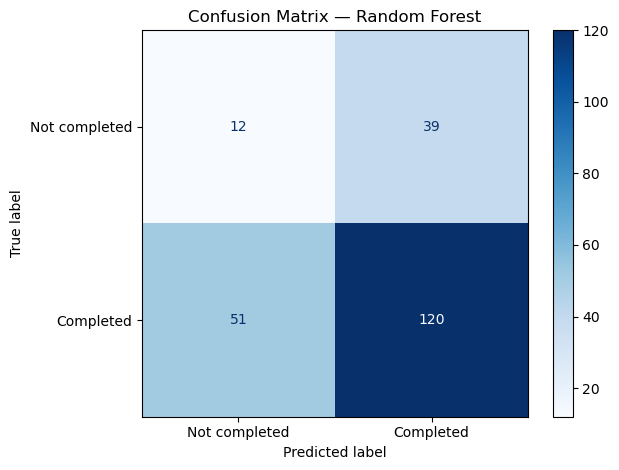

In [82]:
# ============================================
# NEXT CELL: Confusion matrix
# ============================================

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=[
        "Not completed",
        "Completed"
    ],
    cmap="Blues"
)

plt.title(
    f"Confusion Matrix — {best_model_name}"
)

plt.tight_layout()

plt.savefig(
    "ml_referral_completion_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

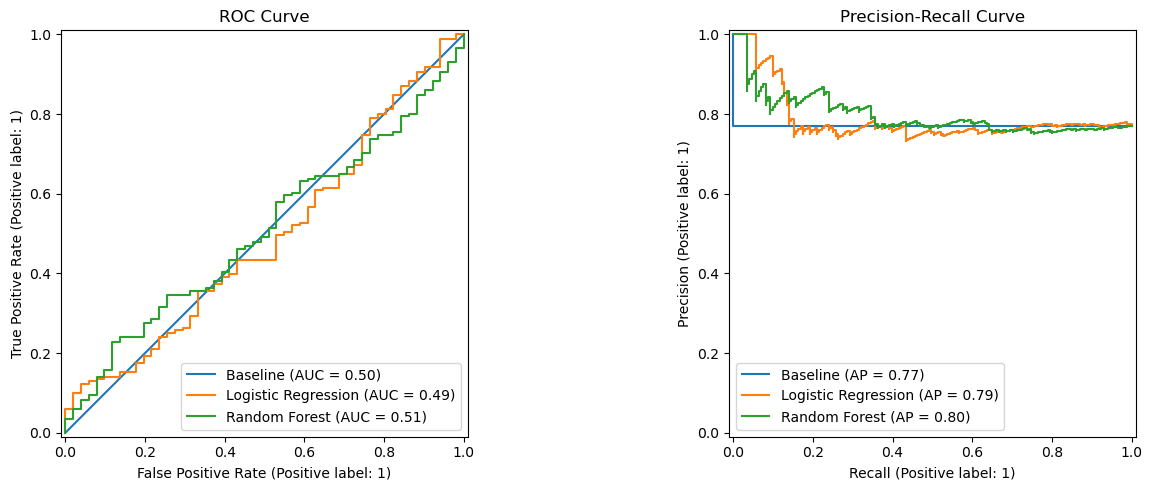

In [83]:
# ============================================
# NEXT CELL: Model comparison curves
# ============================================

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

for model_name, model_pipeline in fitted_models.items():

    probabilities = model_pipeline.predict_proba(
        X_test
    )[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=axes[1]
    )

axes[0].set_title("ROC Curve")
axes[1].set_title("Precision-Recall Curve")

plt.tight_layout()

plt.savefig(
    "ml_referral_completion_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [84]:
# ============================================
# NEXT CELL: Referral follow-up priority list
# ============================================

followup_priority = test_data.copy()

followup_priority[
    "predicted_completion_probability"
] = best_model.predict_proba(
    X_test
)[:, 1]

followup_priority[
    "predicted_noncompletion_risk"
] = (
    1
    - followup_priority[
        "predicted_completion_probability"
    ]
)

followup_priority = followup_priority.sort_values(
    "predicted_noncompletion_risk",
    ascending=False
)

priority_columns = [
    "referral_id_clean",
    "client_id_clean",
    "county",
    "module_clean",
    "facility_name",
    "referral_date_clean",
    "predicted_completion_probability",
    "predicted_noncompletion_risk"
]

priority_columns = [
    column
    for column in priority_columns
    if column in followup_priority.columns
]

followup_priority[
    priority_columns
].head(20)

,referral_id_clean,client_id_clean,county,module_clean,facility_name,referral_date_clean,predicted_completion_probability,predicted_noncompletion_risk
762,R-000156,CL-001283,Kakamega,Malnutrition_Screening,Kakamega Referral Health Centre,2025-11-19,0.336739,0.663261
791,R-001021,CL-009851,Kakamega,Malnutrition_Screening,Kakamega Sub-County Hospital,2025-11-28,0.345127,0.654873
814,R-000123,CL-000973,Kakamega,Malnutrition_Screening,Kakamega Sub-County Hospital,2025-12-07,0.346835,0.653165
676,R-000972,CL-009407,Kakamega,Malnutrition_Screening,Kakamega Sub-County Hospital,2025-10-26,0.358286,0.641714
718,R-000049,CL-000425,Kakamega,Malnutrition_Screening,Kakamega Sub-County Hospital,2025-11-09,0.369405,0.630595
761,R-000588,CL-005513,Kakamega,Malnutrition_Screening,Kakamega Referral Health Centre,2025-11-19,0.373711,0.626289
665,R-000487,CL-004581,Bungoma,Malnutrition_Screening,Bungoma Referral Health Centre,2025-10-24,0.380745,0.619255
821,R-000802,CL-007665,Kakamega,ANC,Kakamega Sub-County Hospital,2025-12-09,0.385207,0.614793
746,R-000812,CL-007716,Bungoma,Malnutrition_Screening,Bungoma Level 4 Hospital,2025-11-15,0.388054,0.611946
734,R-000136,CL-001106,Kakamega,ANC,Kakamega Sub-County Hospital,2025-11-13,0.394133,0.605867


In [85]:
followup_priority.to_csv(
    "ml_referral_followup_priority.csv",
    index=False
)

print(
    "Saved: ml_referral_followup_priority.csv"
)

Saved: ml_referral_followup_priority.csv


In [86]:
# ============================================
# NEXT CELL: Save ML model results
# ============================================

evaluation_results.to_csv(
    "ml_model_evaluation_results.csv",
    index=False
)

print(
    "Saved: ml_model_evaluation_results.csv"
)

Saved: ml_model_evaluation_results.csv


In [87]:
# ============================================
# NEXT CELL: Generate ML report
# ============================================

from IPython.display import Markdown, display

best_result = evaluation_results.iloc[0]

ml_report = f"""
# Optional Machine-Learning Extension

## Objective

The model predicts whether a referral will be completed.

The target was defined as:

- 1 = completed referral
- 0 = not-completed referral

Referrals with blank or unknown outcomes were excluded from modelling.

## Validation approach

A time-based train/test split was used. The earlier 75% of referrals were used
for training, while the later 25% were used for testing.

This approach simulates using historical records to predict future referral
outcomes.

## Models evaluated

The following models were compared:

1. Majority-class baseline
2. Logistic regression
3. Random forest

The best model based on average precision was:

> **{best_model_name}**

## Test-period performance

| Metric | Result |
|---|---:|
| Accuracy | {best_result['accuracy']:.3f} |
| Precision | {best_result['precision']:.3f} |
| Recall | {best_result['recall']:.3f} |
| F1 score | {best_result['f1_score']:.3f} |
| ROC-AUC | {best_result['roc_auc']:.3f} |
| Average precision | {best_result['average_precision']:.3f} |

## Operational use

The model produces a predicted non-completion risk for each referral.

The highest-risk referrals can be prioritized for:

- CHW follow-up
- Facility confirmation
- Supervisor review
- Transport or referral support
- Documentation reconciliation

## Limitations

This model should be treated as a prioritization tool rather than an automated
decision-maker.

The main limitations are:

- The dataset is synthetic.
- The referral sample is limited.
- Training and supervision records are not included.
- Model performance may change on future data.
- Predictions should be reviewed by program staff.
- The model may reproduce existing documentation or access inequalities.
"""

display(Markdown(ml_report))

with open(
    "ml_referral_completion_report.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(ml_report)

print(
    "Saved: ml_referral_completion_report.md"
)


# Optional Machine-Learning Extension

## Objective

The model predicts whether a referral will be completed.

The target was defined as:

- 1 = completed referral
- 0 = not-completed referral

Referrals with blank or unknown outcomes were excluded from modelling.

## Validation approach

A time-based train/test split was used. The earlier 75% of referrals were used
for training, while the later 25% were used for testing.

This approach simulates using historical records to predict future referral
outcomes.

## Models evaluated

The following models were compared:

1. Majority-class baseline
2. Logistic regression
3. Random forest

The best model based on average precision was:

> **Random Forest**

## Test-period performance

| Metric | Result |
|---|---:|
| Accuracy | 0.595 |
| Precision | 0.755 |
| Recall | 0.702 |
| F1 score | 0.727 |
| ROC-AUC | 0.506 |
| Average precision | 0.798 |

## Operational use

The model produces a predicted non-completion risk for each referral.

The highest-risk referrals can be prioritized for:

- CHW follow-up
- Facility confirmation
- Supervisor review
- Transport or referral support
- Documentation reconciliation

## Limitations

This model should be treated as a prioritization tool rather than an automated
decision-maker.

The main limitations are:

- The dataset is synthetic.
- The referral sample is limited.
- Training and supervision records are not included.
- Model performance may change on future data.
- Predictions should be reviewed by program staff.
- The model may reproduce existing documentation or access inequalities.


Saved: ml_referral_completion_report.md


In [88]:
# ============================================
# FINAL ML VALIDATION CHECK
# ============================================

print("Model evaluation results:")
display(evaluation_results.round(3))

baseline_ap = evaluation_results.loc[
    evaluation_results["model"] == "Baseline",
    "average_precision"
].iloc[0]

best_ap = evaluation_results.iloc[0]["average_precision"]

print(f"Baseline average precision: {baseline_ap:.3f}")
print(f"Best model average precision: {best_ap:.3f}")

if best_ap > baseline_ap:
    print(
        "Conclusion: The best model performs better than the baseline "
        "and may be useful for referral follow-up prioritization."
    )
else:
    print(
        "Conclusion: The model does not outperform the baseline. "
        "Do not use it operationally without improving the features or model."
    )

print("\nGenerated files:")
for filename in [
    "ml_model_evaluation_results.csv",
    "ml_referral_followup_priority.csv",
    "ml_referral_completion_confusion_matrix.png",
    "ml_referral_completion_model_comparison.png",
    "ml_referral_completion_report.md"
]:
    print("-", filename)

Model evaluation results:


,model,accuracy,precision,recall,f1_score,roc_auc,average_precision
0,Random Forest,0.595,0.755,0.702,0.727,0.506,0.798
1,Logistic Regression,0.455,0.766,0.421,0.543,0.489,0.789
2,Baseline,0.770,0.770,1.000,0.870,0.500,0.770


Baseline average precision: 0.770
Best model average precision: 0.798
Conclusion: The best model performs better than the baseline and may be useful for referral follow-up prioritization.

Generated files:
- ml_model_evaluation_results.csv
- ml_referral_followup_priority.csv
- ml_referral_completion_confusion_matrix.png
- ml_referral_completion_model_comparison.png
- ml_referral_completion_report.md


In [89]:
# ============================================
# CELL 64: Referral follow-up tracker
# ============================================

from datetime import datetime

# Create a working referral tracker
referral_tracker = referrals_b.copy()

# Add visit information
visit_context = visits_b[
    [
        "visit_id_clean",
        "client_id_clean",
        "chw_id_clean",
        "chu_id_clean",
        "module_clean",
        "danger_sign_present_clean",
        "rdt_result_clean",
        "act_dispensed_clean"
    ]
].copy()

visit_context = visit_context.rename(
    columns={
        "client_id_clean": "visit_client_id_clean",
        "chu_id_clean": "visit_chu_id_clean",
        "chw_id_clean": "visit_chw_id_clean",
        "module_clean": "visit_module_clean"
    }
)

referral_tracker = referral_tracker.merge(
    visit_context,
    on="visit_id_clean",
    how="left"
)

# Add client information
client_context = clients_clean[
    [
        "client_id_clean",
        "household_id_clean",
        "sex",
        "date_of_birth",
        "client_type"
    ]
].copy()

referral_tracker = referral_tracker.merge(
    client_context,
    on="client_id_clean",
    how="left"
)

# Add CHU information
referral_tracker = referral_tracker.merge(
    chus_lookup[
        [
            "chu_id_clean",
            "chu_name",
            "county"
        ]
    ].drop_duplicates("chu_id_clean"),
    on="chu_id_clean",
    how="left",
    suffixes=("", "_lookup")
)

# Add CHW information
referral_tracker = referral_tracker.merge(
    chws_lookup[
        [
            "chw_id_clean",
            "chw_name"
        ]
    ].drop_duplicates("chw_id_clean"),
    left_on="visit_chw_id_clean",
    right_on="chw_id_clean",
    how="left"
)

# Calculate days since referral
reference_date = pd.Timestamp.today().normalize()

referral_tracker["days_since_referral"] = (
    reference_date
    - referral_tracker["referral_date_clean"]
).dt.days

# Standardize outcome status
referral_tracker["outcome_status"] = (
    referral_tracker["outcome_clean"]
    .fillna("unknown")
)

# Create priority rules
referral_tracker["priority_reason"] = ""

referral_tracker.loc[
    referral_tracker["outcome_status"].isin(
        ["unknown", "not_completed"]
    ),
    "priority_reason"
] = "Outcome unresolved or referral not completed"

referral_tracker.loc[
    referral_tracker["danger_sign_present_clean"] == True,
    "priority_reason"
] = (
    referral_tracker["priority_reason"]
    + "; danger sign present"
)

referral_tracker.loc[
    referral_tracker["days_since_referral"] >= 14,
    "priority_reason"
] = (
    referral_tracker["priority_reason"]
    + "; referral older than 14 days"
)

# Assign operational priority
referral_tracker["followup_priority"] = "Low"

referral_tracker.loc[
    (
        referral_tracker["outcome_status"]
        .isin(["unknown", "not_completed"])
    ),
    "followup_priority"
] = "Medium"

referral_tracker.loc[
    (
        referral_tracker["outcome_status"]
        .isin(["unknown", "not_completed"])
    )
    & (
        referral_tracker["days_since_referral"] >= 14
    ),
    "followup_priority"
] = "High"

referral_tracker.loc[
    (
        referral_tracker["danger_sign_present_clean"] == True
    )
    & (
        referral_tracker["outcome_status"]
        .isin(["unknown", "not_completed"])
    ),
    "followup_priority"
] = "High"

# Display highest-priority referrals
referral_tracker[
    referral_tracker["followup_priority"] == "High"
][
    [
        "referral_id_clean",
        "client_id_clean",
        "county",
        "chu_name",
        "chw_name",
        "module_clean",
        "facility_name",
        "referral_date_clean",
        "outcome_status",
        "days_since_referral",
        "followup_priority",
        "priority_reason"
    ]
].head(20)

,referral_id_clean,client_id_clean,county,chu_name,chw_name,module_clean,facility_name,referral_date_clean,outcome_status,days_since_referral,followup_priority,priority_reason
1,R-000737,CL-007073,Bungoma,Bungoma CHU 2,Chebet Simiyu,ANC,Bungoma Referral Health Centre,2025-09-15,not_completed,359,High,Outcome unresolved or referral not completed; ...
5,R-000010,CL-000044,Kisumu,Kisumu CHU 2,Nyambura Odongo,Malnutrition_Screening,Kisumu Level 4 Hospital,2025-11-11,unknown,302,High,Outcome unresolved or referral not completed; ...
6,R-000135,CL-001103,Nyeri,Nyeri CHU 2,Wanjiru Kip,PNC,Nyeri Level 4 Hospital,2025-08-20,unknown,385,High,Outcome unresolved or referral not completed; ...
7,R-000778,CL-007446,Machakos,Machakos CHU 2,Nyambura Njoroge,Malnutrition_Screening,Machakos Level 4 Hospital,2025-11-19,unknown,294,High,Outcome unresolved or referral not completed; ...
8,R-000410,CL-003629,Machakos,Machakos CHU 3,Wafula Kilonzo,Malaria_Case,Machakos Level 4 Hospital,2025-12-18,unknown,265,High,Outcome unresolved or referral not completed; ...
17,R-000768,CL-007356,Kakamega,Kakamega CHU 2,Kiplagat Kilonzo,PNC,Kakamega Referral Health Centre,2025-09-17,not_completed,357,High,Outcome unresolved or referral not completed; ...
20,R-000488,CL-004581,Bungoma,Bungoma CHU 2,Wairimu Kilonzo,Malnutrition_Screening,Bungoma Referral Health Centre,2025-04-05,not_completed,522,High,Outcome unresolved or referral not completed; ...
26,R-000396,CL-003494,Bungoma,Bungoma CHU 3,Kiptoo Kip,ANC,Bungoma Level 4 Hospital,2025-09-11,not_completed,363,High,Outcome unresolved or referral not completed; ...
27,R-001004,CL-009671,Kilifi,Kilifi CHU 2,Otieno Njoroge,Malnutrition_Screening,Kilifi Referral Health Centre,2025-06-19,not_completed,447,High,Outcome unresolved or referral not completed; ...
35,R-000919,CL-008757,Kakamega,Kakamega CHU 2,Wanjiru Njoroge,Malaria_Case,Kakamega Level 4 Hospital,2025-05-22,not_completed,475,High,Outcome unresolved or referral not completed; ...


In [90]:
# ============================================
# CELL 65: Export referral tracker
# ============================================

referral_tracker_output = referral_tracker[
    [
        "referral_id_clean",
        "client_id_clean",
        "county",
        "chu_name",
        "chw_name",
        "module_clean",
        "facility_name",
        "referral_date_clean",
        "outcome_status",
        "days_since_referral",
        "followup_priority",
        "priority_reason"
    ]
].copy()

referral_tracker_output = referral_tracker_output.sort_values(
    [
        "followup_priority",
        "days_since_referral"
    ],
    ascending=[True, False]
)

referral_tracker_output.to_csv(
    "operational_referral_followup_tracker.csv",
    index=False
)

print(
    "Saved operational_referral_followup_tracker.csv"
)

Saved operational_referral_followup_tracker.csv


In [91]:
# ============================================
# CELL 66: Referral follow-up summary
# ============================================

referral_followup_summary = (
    referral_tracker_output
    .groupby(
        [
            "county",
            "module_clean",
            "followup_priority"
        ]
    )
    .size()
    .reset_index(
        name="referral_count"
    )
)

referral_followup_summary

,county,module_clean,followup_priority,referral_count
0,Bungoma,ANC,High,14
1,Bungoma,ANC,Low,26
2,Bungoma,Malaria_Case,High,14
3,Bungoma,Malaria_Case,Low,37
4,Bungoma,Malnutrition_Screening,High,12
5,Bungoma,Malnutrition_Screening,Low,34
6,Bungoma,PNC,High,5
7,Bungoma,PNC,Low,4
8,Kakamega,ANC,High,21
9,Kakamega,ANC,Low,62


In [93]:
# ============================================
# REPLACEMENT CELL 67:
# CHV workload dashboard
# ============================================

# Rebuild the CHU lookup with population_target included
chus_lookup = (
    chus_clean[
        [
            "chu_id_clean",
            "chu_name",
            "county",
            "population_target"
        ]
    ]
    .drop_duplicates("chu_id_clean")
)

# Rebuild the CHW lookup
chws_lookup = (
    chws_clean[
        [
            "chw_id_clean",
            "chw_name",
            "chu_id_clean"
        ]
    ]
    .drop_duplicates("chw_id_clean")
)

# Prepare visits
visits_workload = visits_b.copy()

visits_workload["active_month"] = (
    visits_workload["visit_date_clean"]
    .dt.to_period("M")
)

# Calculate CHV workload
chw_workload = (
    visits_workload
    .groupby("chw_id_clean")
    .agg(
        total_visits=("visit_id_clean", "count"),
        active_months=("active_month", "nunique"),
        clients_seen=("client_id_clean", "nunique"),
        chu_id_clean=("chu_id_clean", "first"),
        first_visit=("visit_date_clean", "min"),
        last_visit=("visit_date_clean", "max")
    )
    .reset_index()
)

chw_workload["average_visits_per_active_month"] = (
    chw_workload["total_visits"]
    / chw_workload["active_months"]
)

# Add CHV names
chw_workload = chw_workload.merge(
    chws_lookup[
        [
            "chw_id_clean",
            "chw_name"
        ]
    ],
    on="chw_id_clean",
    how="left"
)

# Add CHU details using the same cleaned identifier
chw_workload = chw_workload.merge(
    chus_lookup[
        [
            "chu_id_clean",
            "chu_name",
            "county",
            "population_target"
        ]
    ],
    on="chu_id_clean",
    how="left"
)

chw_workload = chw_workload.sort_values(
    "total_visits",
    ascending=False
)

chw_workload.head(20)

,chw_id_clean,total_visits,active_months,clients_seen,chu_id_clean,first_visit,last_visit,average_visits_per_active_month,chw_name,chu_name,county,population_target
20,CHV-0021,1232,12,597,CHU-KAK-02,2025-01-01,2025-12-31,102.666667,Kiplagat Mburu,Kakamega CHU 2,Kakamega,5881
22,CHV-0023,1229,12,583,CHU-KAK-02,2025-01-01,2025-12-31,102.416667,Kiplagat Kilonzo,Kakamega CHU 2,Kakamega,5881
21,CHV-0022,1205,12,592,CHU-KAK-02,2025-01-01,2025-12-31,100.416667,Wanjiru Njoroge,Kakamega CHU 2,Kakamega,5881
41,CHV-0042,725,12,338,CHU-KLF-01,2025-01-01,2025-12-31,60.416667,Mutua Simiyu,Kilifi CHU 1,Kilifi,4017
67,CHV-0068,719,12,424,CHU-NYR-02,2025-01-01,2025-12-31,59.916667,Wairimu Kilonzo,Nyeri CHU 2,Nyeri,6322
42,CHV-0043,714,12,347,CHU-KLF-01,2025-01-02,2025-12-30,59.500000,Kiptoo Odongo,Kilifi CHU 1,Kilifi,4017
40,CHV-0041,712,12,340,CHU-KLF-01,2025-01-01,2025-12-31,59.333333,Kiplagat Onyango,Kilifi CHU 1,Kilifi,4017
70,CHV-0071,680,12,401,CHU-NYR-02,2025-01-01,2025-12-31,56.666667,Wanjiru Kip,Nyeri CHU 2,Nyeri,6322
68,CHV-0069,678,12,425,CHU-NYR-02,2025-01-02,2025-12-31,56.500000,Odhiambo Kariuki,Nyeri CHU 2,Nyeri,6322
69,CHV-0070,675,12,415,CHU-NYR-02,2025-01-02,2025-12-31,56.250000,Wanjiru Odongo,Nyeri CHU 2,Nyeri,6322


In [94]:
# ============================================
# CELL 68: CHV workload alerts
# ============================================

high_volume_threshold = (
    chw_workload["total_visits"].quantile(0.90)
)

low_volume_threshold = (
    chw_workload["total_visits"].quantile(0.10)
)

chw_workload["workload_alert"] = "Normal"

chw_workload.loc[
    chw_workload["total_visits"]
    >= high_volume_threshold,
    "workload_alert"
] = "High workload"

chw_workload.loc[
    chw_workload["total_visits"]
    <= low_volume_threshold,
    "workload_alert"
] = "Low workload"

chw_workload[
    [
        "chw_id_clean",
        "chw_name",
        "chu_name",
        "county",
        "total_visits",
        "active_months",
        "average_visits_per_active_month",
        "workload_alert"
    ]
]

,chw_id_clean,chw_name,chu_name,county,total_visits,active_months,average_visits_per_active_month,workload_alert
20,CHV-0021,Kiplagat Mburu,Kakamega CHU 2,Kakamega,1232,12,102.666667,High workload
22,CHV-0023,Kiplagat Kilonzo,Kakamega CHU 2,Kakamega,1229,12,102.416667,High workload
21,CHV-0022,Wanjiru Njoroge,Kakamega CHU 2,Kakamega,1205,12,100.416667,High workload
41,CHV-0042,Mutua Simiyu,Kilifi CHU 1,Kilifi,725,12,60.416667,High workload
67,CHV-0068,Wairimu Kilonzo,Nyeri CHU 2,Nyeri,719,12,59.916667,High workload
...,...,...,...,...,...,...,...,...
11,CHV-0012,Auma Onyango,Kisumu CHU 3,Kisumu,106,12,8.833333,Low workload
30,CHV-0031,Nafula Onyango,Machakos CHU 1,Machakos,100,12,8.333333,Low workload
12,CHV-0013,Otieno Kip,Kisumu CHU 3,Kisumu,98,12,8.166667,Low workload
14,CHV-0015,Cherono Owino,Kisumu CHU 3,Kisumu,90,12,7.500000,Low workload


In [95]:
# ============================================
# CELL 69: CHU data-quality scorecard
# ============================================

# Count visits by CHU
chu_visit_quality = (
    visits_clean
    .groupby("chu_id_clean")
    .agg(
        total_visit_records=("visit_id_clean", "count"),
        flagged_visit_records=("any_quality_flag", "sum")
    )
    .reset_index()
)

# Count referrals by CHU
chu_referral_quality = (
    referrals_clean
    .groupby("chu_id_clean")
    .agg(
        total_referral_records=("referral_id_clean", "count"),
        flagged_referral_records=("any_quality_flag", "sum")
    )
    .reset_index()
)

# Combine the two quality tables
chu_quality = chu_visit_quality.merge(
    chu_referral_quality,
    on="chu_id_clean",
    how="outer"
).fillna(0)

chu_quality["total_records"] = (
    chu_quality["total_visit_records"]
    + chu_quality["total_referral_records"]
)

chu_quality["flagged_records"] = (
    chu_quality["flagged_visit_records"]
    + chu_quality["flagged_referral_records"]
)

chu_quality["data_quality_score_pct"] = (
    1
    - chu_quality["flagged_records"]
    / chu_quality["total_records"]
) * 100

# Add CHU details
chu_quality = chu_quality.merge(
    chus_lookup[
        [
            "chu_id_clean",
            "chu_name",
            "county"
        ]
    ].drop_duplicates("chu_id_clean"),
    on="chu_id_clean",
    how="left"
)

chu_quality = chu_quality.sort_values(
    "data_quality_score_pct"
)

chu_quality

,chu_id_clean,total_visit_records,flagged_visit_records,total_referral_records,flagged_referral_records,total_records,flagged_records,data_quality_score_pct,chu_name,county
8,CHU-KLF-03,404,20,23,3,427,23,94.613583,Kilifi CHU 3,Kilifi
15,CHU-NYR-01,720,23,29,7,749,30,95.99466,Nyeri CHU 1,Nyeri
13,CHU-MCK-02,877,28,31,3,908,31,96.585903,Machakos CHU 2,Machakos
10,CHU-KSM-02,1672,52,66,7,1738,59,96.605293,Kisumu CHU 2,Kisumu
17,CHU-NYR-03,2087,64,80,9,2167,73,96.631287,Nyeri CHU 3,Nyeri
3,CHU-KAK-01,1981,58,77,9,2058,67,96.744412,Kakamega CHU 1,Kakamega
11,CHU-KSM-03,533,16,21,2,554,18,96.750903,Kisumu CHU 3,Kisumu
1,CHU-BGM-02,1591,47,57,6,1648,53,96.783981,Bungoma CHU 2,Bungoma
14,CHU-MCK-03,705,21,22,2,727,23,96.836314,Machakos CHU 3,Machakos
9,CHU-KSM-01,1151,34,62,3,1213,37,96.949711,Kisumu CHU 1,Kisumu


In [97]:
# ============================================
# REPLACEMENT CELL 70:
# Combine CHU operational scorecard
# ============================================

# -----------------------------
# Malaria summary by CHU
# -----------------------------

malaria_scorecard = malaria_by_chu[
    [
        "chu_id_clean",
        "malaria_visits",
        "rdt_positivity_rate_pct",
        "act_dispensing_rate_positive_pct"
    ]
].copy()

# -----------------------------
# Referral summary by CHU
# -----------------------------

referrals_for_scorecard = referrals_b.copy()

referrals_for_scorecard["known_outcome"] = (
    referrals_for_scorecard["outcome_clean"]
    .isin(
        [
            "completed",
            "not_completed"
        ]
    )
)

referrals_for_scorecard["completed"] = (
    referrals_for_scorecard["outcome_clean"]
    == "completed"
)

referral_scorecard = (
    referrals_for_scorecard
    .groupby("chu_id_clean")
    .agg(
        total_referrals=("referral_id_clean", "count"),
        known_referral_outcomes=("known_outcome", "sum"),
        completed_referrals=("completed", "sum")
    )
    .reset_index()
)

referral_scorecard[
    "referral_completion_rate_pct"
] = np.where(
    referral_scorecard[
        "known_referral_outcomes"
    ] > 0,
    referral_scorecard[
        "completed_referrals"
    ]
    / referral_scorecard[
        "known_referral_outcomes"
    ]
    * 100,
    np.nan
)

# -----------------------------
# CHV workload summary by CHU
# -----------------------------

workload_scorecard = (
    chw_workload
    .groupby("chu_id_clean")
    .agg(
        total_chv_visits=("total_visits", "sum"),
        active_chvs=("chw_id_clean", "nunique"),
        average_chv_visits_per_month=(
            "average_visits_per_active_month",
            "mean"
        )
    )
    .reset_index()
)

# -----------------------------
# Combine all indicators
# -----------------------------

chu_operational_scorecard = (
    chus_lookup[
        [
            "chu_id_clean",
            "chu_name",
            "county",
            "population_target"
        ]
    ]
    .drop_duplicates("chu_id_clean")
    .merge(
        malaria_scorecard,
        on="chu_id_clean",
        how="left"
    )
    .merge(
        referral_scorecard,
        on="chu_id_clean",
        how="left"
    )
    .merge(
        workload_scorecard,
        on="chu_id_clean",
        how="left"
    )
    .merge(
        chu_quality[
            [
                "chu_id_clean",
                "data_quality_score_pct",
                "flagged_records"
            ]
        ],
        on="chu_id_clean",
        how="left"
    )
)

chu_operational_scorecard

,chu_id_clean,chu_name,county,population_target,malaria_visits,rdt_positivity_rate_pct,act_dispensing_rate_positive_pct,total_referrals,known_referral_outcomes,completed_referrals,referral_completion_rate_pct,total_chv_visits,active_chvs,average_chv_visits_per_month,data_quality_score_pct,flagged_records
0,CHU-KSM-01,Kisumu CHU 1,Kisumu,3990,232,40.291262,0.0,62,52,38,73.076923,1148,5,19.133333,96.949711,37
1,CHU-KSM-02,Kisumu CHU 2,Kisumu,7756,371,36.686391,0.0,66,56,47,83.928571,1665,5,27.750000,96.605293,59
2,CHU-KSM-03,Kisumu CHU 3,Kisumu,7100,100,35.955056,0.0,21,19,12,63.157895,532,5,8.866667,96.750903,18
3,CHU-KAK-01,Kakamega CHU 1,Kakamega,5913,379,37.971014,0.0,77,62,48,77.419355,1974,5,32.900000,96.744412,67
4,CHU-KAK-02,Kakamega CHU 2,Kakamega,5881,703,33.950617,0.0,146,130,90,69.230769,3666,3,101.833333,97.391077,100
5,CHU-KAK-03,Kakamega CHU 3,Kakamega,8222,304,35.815603,0.0,36,29,22,75.862069,1457,5,24.283333,97.464977,38
6,CHU-MCK-01,Machakos CHU 1,Machakos,3972,85,37.974684,0.0,12,12,9,75.000000,417,4,8.687500,97.44186,11
7,CHU-MCK-02,Machakos CHU 2,Machakos,7335,189,39.306358,0.0,31,27,24,88.888889,875,5,14.583333,96.585903,31
8,CHU-MCK-03,Machakos CHU 3,Machakos,4608,165,32.885906,0.0,22,19,13,68.421053,702,3,19.500000,96.836314,23
9,CHU-KLF-01,Kilifi CHU 1,Kilifi,4017,444,36.775819,0.0,91,78,64,82.051282,2151,3,59.750000,96.975089,68


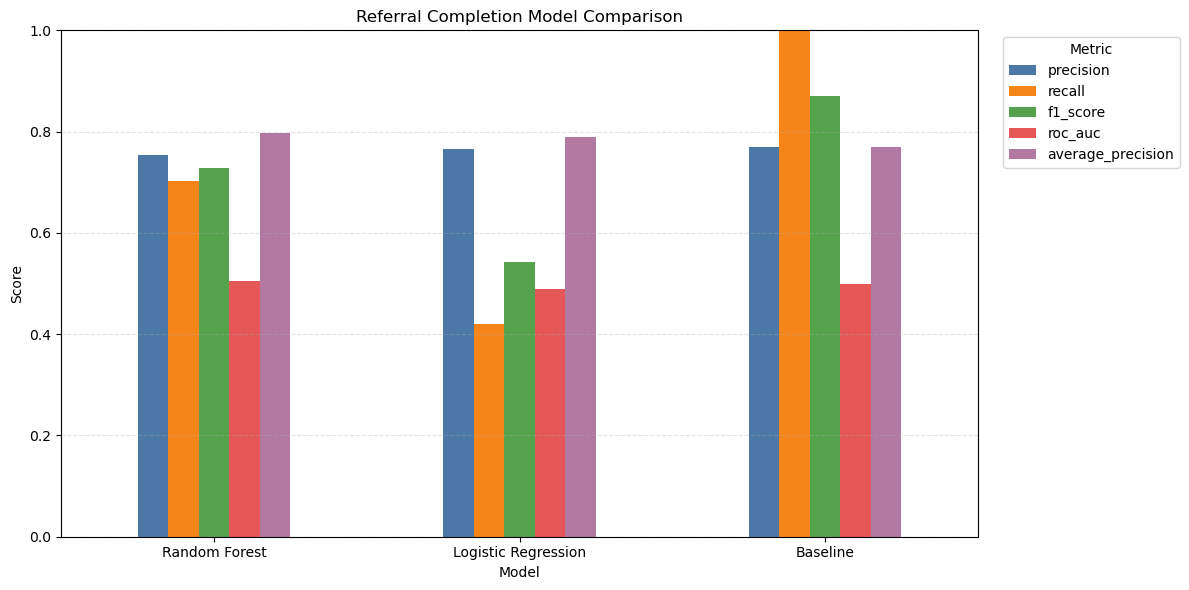

In [98]:
# ============================================
# CELL 72: Model comparison chart
# ============================================

metrics_to_plot = [
    "precision",
    "recall",
    "f1_score",
    "roc_auc",
    "average_precision"
]

model_plot = evaluation_results.set_index(
    "model"
)[metrics_to_plot]

ax = model_plot.plot(
    kind="bar",
    figsize=(12, 6),
    color=[
        "#4C78A8",
        "#F58518",
        "#54A24B",
        "#E45756",
        "#B279A2"
    ]
)

ax.set_title(
    "Referral Completion Model Comparison"
)

ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "ml_chart_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

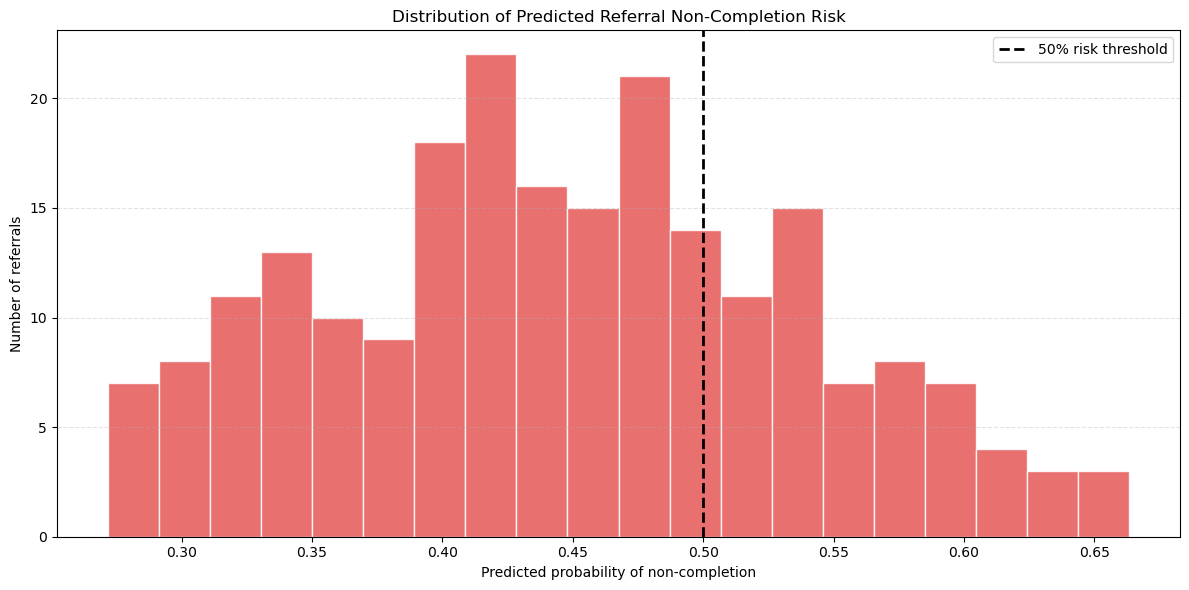

In [99]:
# ============================================
# CELL 73: Predicted risk distribution
# ============================================

risk_values = followup_priority[
    "predicted_noncompletion_risk"
]

plt.figure(figsize=(12, 6))

plt.hist(
    risk_values,
    bins=20,
    color="#E45756",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    0.50,
    color="black",
    linestyle="--",
    linewidth=2,
    label="50% risk threshold"
)

plt.title(
    "Distribution of Predicted Referral Non-Completion Risk"
)

plt.xlabel(
    "Predicted probability of non-completion"
)

plt.ylabel(
    "Number of referrals"
)

plt.legend()
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()

plt.savefig(
    "ml_chart_predicted_risk_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/var/folders/11/6k_34l494h9cm0p_k_mk05zm0000gp/T/ipykernel_10145/2132993152.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


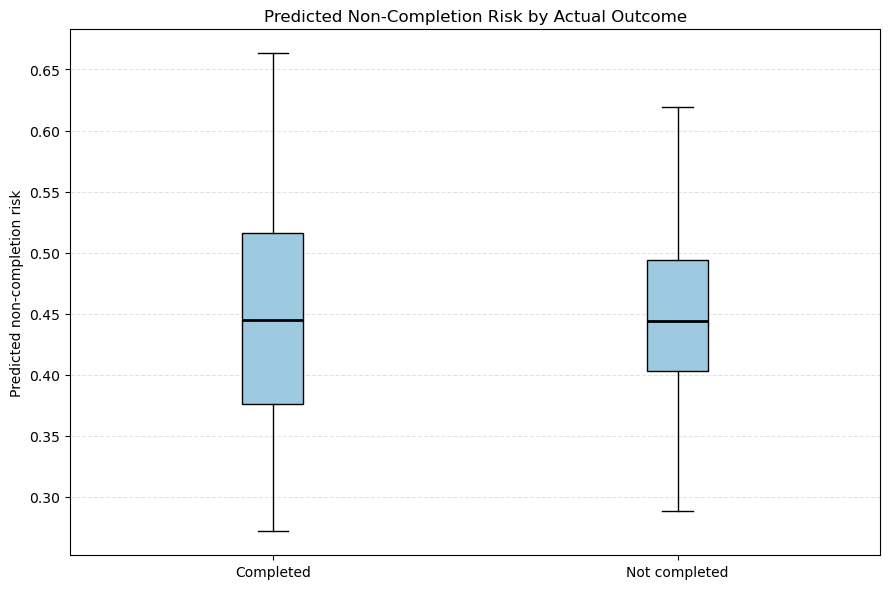

In [100]:
# ============================================
# CELL 74: Predicted risk by actual outcome
# ============================================

risk_plot = followup_priority.copy()

risk_plot["actual_outcome"] = np.where(
    risk_plot["referral_completed"] == 1,
    "Completed",
    "Not completed"
)

groups = [
    risk_plot.loc[
        risk_plot["actual_outcome"] == "Completed",
        "predicted_noncompletion_risk"
    ],
    risk_plot.loc[
        risk_plot["actual_outcome"] == "Not completed",
        "predicted_noncompletion_risk"
    ]
]

plt.figure(figsize=(9, 6))

plt.boxplot(
    groups,
    labels=[
        "Completed",
        "Not completed"
    ],
    patch_artist=True,
    boxprops=dict(
        facecolor="#9ecae1"
    ),
    medianprops=dict(
        color="black",
        linewidth=2
    )
)

plt.title(
    "Predicted Non-Completion Risk by Actual Outcome"
)

plt.ylabel(
    "Predicted non-completion risk"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()

plt.savefig(
    "ml_chart_risk_by_actual_outcome.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

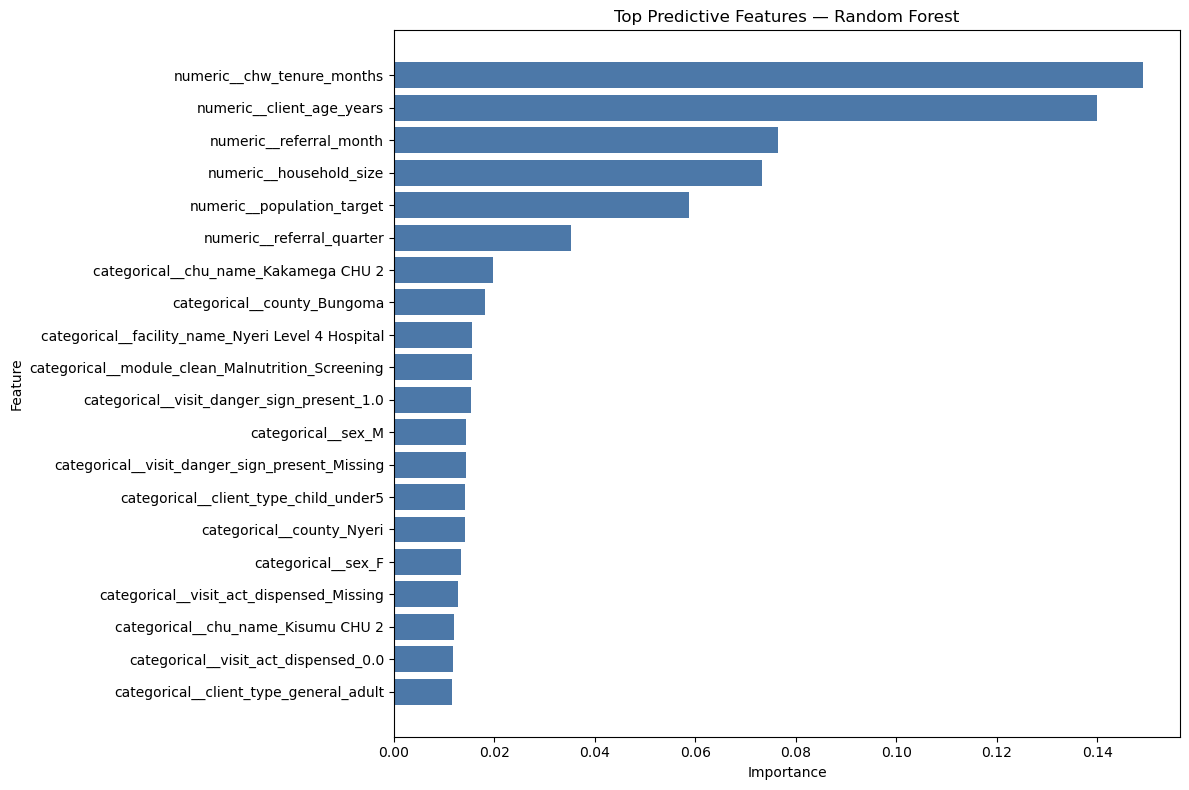

In [101]:
# ============================================
# CELL 75: Feature importance
# ============================================

best_preprocessor = best_model.named_steps[
    "preprocessor"
]

best_estimator = best_model.named_steps[
    "model"
]

feature_names = (
    best_preprocessor
    .get_feature_names_out()
)

if hasattr(best_estimator, "feature_importances_"):

    importance_values = (
        best_estimator.feature_importances_
    )

elif hasattr(best_estimator, "coef_"):

    importance_values = np.abs(
        best_estimator.coef_[0]
    )

else:
    raise TypeError(
        "The selected model does not expose feature importance."
    )

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_values
})

feature_importance = (
    feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
    .head(20)
    .sort_values(
        "importance",
        ascending=True
    )
)

plt.figure(figsize=(12, 8))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"],
    color="#4C78A8"
)

plt.title(
    f"Top Predictive Features — {best_model_name}"
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.savefig(
    "ml_chart_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

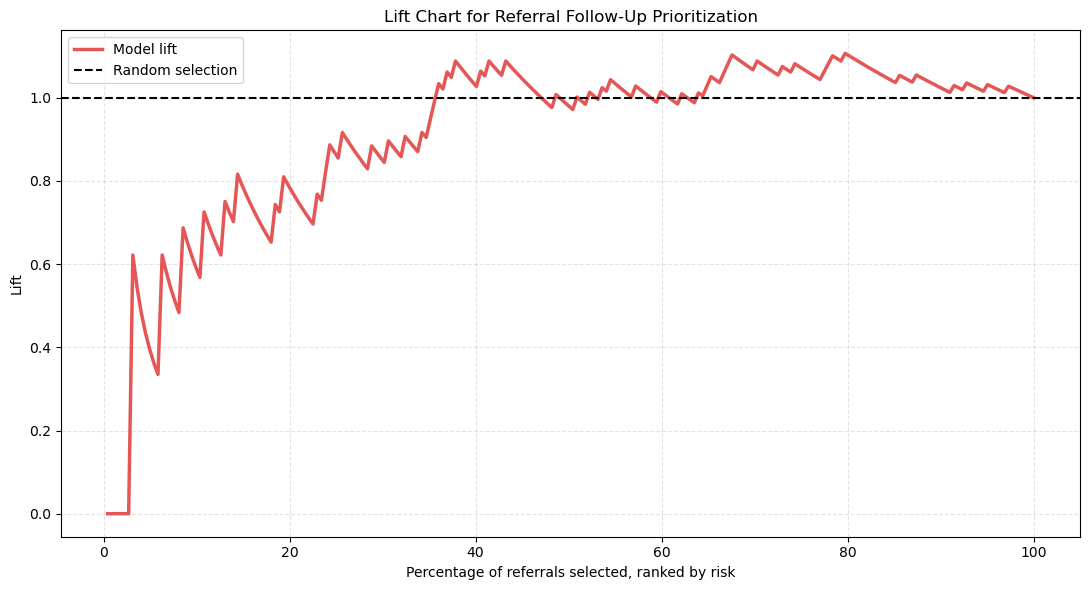

In [102]:
# ============================================
# CELL 76: Lift chart
# ============================================

lift_data = followup_priority.copy()

# Sort highest predicted risk first
lift_data = lift_data.sort_values(
    "predicted_noncompletion_risk",
    ascending=False
).reset_index(drop=True)

lift_data["rank"] = np.arange(
    1,
    len(lift_data) + 1
)

lift_data["cumulative_incomplete"] = (
    1 - lift_data["referral_completed"]
).cumsum()
    
lift_data["cumulative_incomplete_rate"] = (
    lift_data["cumulative_incomplete"]
    /
    lift_data["rank"]
)

overall_incomplete_rate = (
    1 - lift_data["referral_completed"].mean()
)

lift_data["lift"] = (
    lift_data["cumulative_incomplete_rate"]
    / overall_incomplete_rate
)

lift_data["population_percentile"] = (
    lift_data["rank"]
    / len(lift_data)
    * 100
)

plt.figure(figsize=(11, 6))

plt.plot(
    lift_data["population_percentile"],
    lift_data["lift"],
    linewidth=2.5,
    color="#E45756",
    label="Model lift"
)

plt.axhline(
    1,
    color="black",
    linestyle="--",
    label="Random selection"
)

plt.title(
    "Lift Chart for Referral Follow-Up Prioritization"
)

plt.xlabel(
    "Percentage of referrals selected, ranked by risk"
)

plt.ylabel(
    "Lift"
)

plt.legend()
plt.grid(
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()

plt.savefig(
    "ml_chart_lift_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

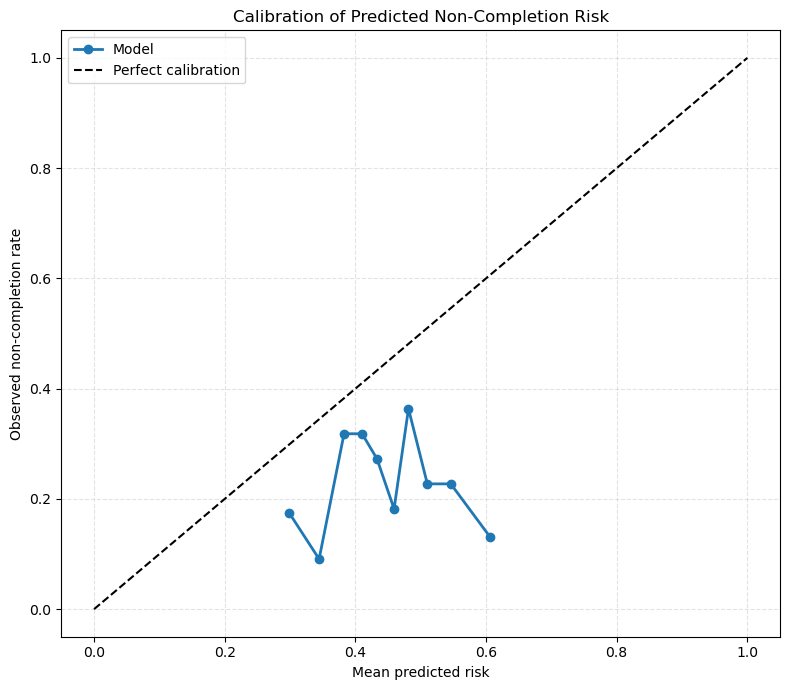

In [103]:
# ============================================
# CELL 77: Calibration curve
# ============================================

from sklearn.calibration import calibration_curve

best_probabilities = best_model.predict_proba(
    X_test
)[:, 1]

# Convert completion probability to non-completion probability
predicted_noncompletion = (
    1 - best_probabilities
)

actual_noncompletion = (
    1 - y_test
)

fraction_observed, mean_predicted = (
    calibration_curve(
        actual_noncompletion,
        predicted_noncompletion,
        n_bins=10,
        strategy="quantile"
    )
)

plt.figure(figsize=(8, 7))

plt.plot(
    mean_predicted,
    fraction_observed,
    marker="o",
    linewidth=2,
    label="Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Perfect calibration"
)

plt.title(
    "Calibration of Predicted Non-Completion Risk"
)

plt.xlabel(
    "Mean predicted risk"
)

plt.ylabel(
    "Observed non-completion rate"
)

plt.legend()
plt.grid(
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()

plt.savefig(
    "ml_chart_calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [104]:
# ============================================
# CELL 78: Build data-quality ML dataset
# ============================================

# Use 2025 visits only
quality_data = visits_clean[
    visits_clean["visit_date_clean"].between(
        "2025-01-01",
        "2025-12-31"
    )
].copy()

# Keep only the fields needed for modelling
quality_data = quality_data[
    [
        "visit_id_clean",
        "county",
        "module_clean",
        "chu_id_clean",
        "chw_id_clean",
        "client_id_clean",
        "visit_date_clean",
        "any_quality_flag"
    ]
].copy()

# Create the target
quality_data["quality_risk"] = (
    quality_data["any_quality_flag"]
    .astype(int)
)

# Add client information
quality_client_features = clients_clean[
    [
        "client_id_clean",
        "household_id_clean",
        "sex",
        "date_of_birth",
        "client_type"
    ]
].copy()

quality_client_features["date_of_birth"] = pd.to_datetime(
    quality_client_features["date_of_birth"],
    errors="coerce"
)

quality_data = quality_data.merge(
    quality_client_features,
    on="client_id_clean",
    how="left"
)

# Add household information
quality_household_features = households_clean[
    [
        "household_id_clean",
        "household_size"
    ]
].copy()

quality_data = quality_data.merge(
    quality_household_features,
    on="household_id_clean",
    how="left"
)

# Add CHW information
quality_chw_features = chws_clean[
    [
        "chw_id_clean",
        "registration_date"
    ]
].copy()

quality_chw_features["registration_date"] = pd.to_datetime(
    quality_chw_features["registration_date"],
    errors="coerce"
)

quality_data = quality_data.merge(
    quality_chw_features,
    on="chw_id_clean",
    how="left"
)

# Add CHU information
quality_chu_features = chus_clean[
    [
        "chu_id_clean",
        "chu_name",
        "population_target"
    ]
].drop_duplicates(
    "chu_id_clean"
)

quality_data = quality_data.merge(
    quality_chu_features,
    on="chu_id_clean",
    how="left"
)

print("Quality modelling rows:", len(quality_data))
print("\nTarget distribution:")
print(quality_data["quality_risk"].value_counts())
print("\nTarget proportions:")
print(quality_data["quality_risk"].value_counts(normalize=True))

Quality modelling rows: 26668

Target distribution:
quality_risk
0    26022
1      646
Name: count, dtype: int64

Target proportions:
quality_risk
0    0.975776
1    0.024224
Name: proportion, dtype: float64


In [105]:
# ============================================
# CELL 79: Engineer quality-risk features
# ============================================

# Month and quarter
quality_data["visit_month"] = (
    quality_data["visit_date_clean"].dt.month
)

quality_data["visit_quarter"] = (
    quality_data["visit_date_clean"].dt.quarter
)

# Client age at visit
quality_data["client_age_years"] = (
    (
        quality_data["visit_date_clean"]
        - quality_data["date_of_birth"]
    ).dt.days / 365.25
)

# CHW tenure at visit
quality_data["chw_tenure_months"] = (
    (
        quality_data["visit_date_clean"]
        - quality_data["registration_date"]
    ).dt.days / 30.44
)

# Remove impossible values
quality_data.loc[
    (quality_data["client_age_years"] < 0)
    | (quality_data["client_age_years"] > 120),
    "client_age_years"
] = np.nan

quality_data.loc[
    quality_data["chw_tenure_months"] < 0,
    "chw_tenure_months"
] = np.nan

# Do not use any fields that directly define the quality flag.
# For example, do not include MUAC, referral outcome,
# RDT result, or missingness flags as predictors.

quality_features = [
    "county",
    "module_clean",
    "chu_id_clean",
    "chw_id_clean",
    "visit_month",
    "visit_quarter",
    "sex",
    "client_type",
    "client_age_years",
    "household_size",
    "chw_tenure_months",
    "population_target"
]

quality_features = [
    column
    for column in quality_features
    if column in quality_data.columns
]

X_quality = quality_data[
    quality_features
].copy()

y_quality = quality_data[
    "quality_risk"
].copy()

print("Quality-model features:")
print(quality_features)

Quality-model features:
['county', 'module_clean', 'chu_id_clean', 'chw_id_clean', 'visit_month', 'visit_quarter', 'sex', 'client_type', 'client_age_years', 'household_size', 'chw_tenure_months', 'population_target']


In [106]:
# ============================================
# CELL 80: Time-based quality-risk split
# ============================================

quality_data = quality_data.sort_values(
    "visit_date_clean"
).reset_index(drop=True)

split_index = int(
    len(quality_data) * 0.75
)

train_quality = quality_data.iloc[
    :split_index
].copy()

test_quality = quality_data.iloc[
    split_index:
].copy()

X_quality_train = train_quality[
    quality_features
].copy()

X_quality_test = test_quality[
    quality_features
].copy()

y_quality_train = train_quality[
    "quality_risk"
].copy()

y_quality_test = test_quality[
    "quality_risk"
].copy()

print("Training rows:", len(train_quality))
print("Testing rows:", len(test_quality))

print("\nTraining quality-risk distribution:")
print(y_quality_train.value_counts())

print("\nTesting quality-risk distribution:")
print(y_quality_test.value_counts())

Training rows: 20001
Testing rows: 6667

Training quality-risk distribution:
quality_risk
0    19546
1      455
Name: count, dtype: int64

Testing quality-risk distribution:
quality_risk
0    6476
1     191
Name: count, dtype: int64


In [107]:
# ============================================
# CELL 81: Make quality features sklearn-safe
# ============================================

quality_categorical_features = [
    column
    for column in quality_features
    if (
        X_quality_train[column].dtype == "object"
        or str(
            X_quality_train[column].dtype
        ).startswith("string")
        or str(
            X_quality_train[column].dtype
        ).startswith("category")
    )
]

quality_numeric_features = [
    column
    for column in quality_features
    if column not in quality_categorical_features
]

# Convert numeric columns
for column in quality_numeric_features:
    X_quality_train[column] = pd.to_numeric(
        X_quality_train[column],
        errors="coerce"
    ).astype(float)

    X_quality_test[column] = pd.to_numeric(
        X_quality_test[column],
        errors="coerce"
    ).astype(float)

# Convert categorical columns
for column in quality_categorical_features:
    X_quality_train[column] = (
        X_quality_train[column]
        .astype("string")
        .fillna("Missing")
        .astype(object)
    )

    X_quality_test[column] = (
        X_quality_test[column]
        .astype("string")
        .fillna("Missing")
        .astype(object)
    )

# Replace pandas NA with numpy nan
X_quality_train = X_quality_train.replace(
    {pd.NA: np.nan}
)

X_quality_test = X_quality_test.replace(
    {pd.NA: np.nan}
)

print("Categorical features:")
print(quality_categorical_features)

print("\nNumeric features:")
print(quality_numeric_features)

Categorical features:
['county', 'module_clean', 'chu_id_clean', 'chw_id_clean', 'sex', 'client_type']

Numeric features:
['visit_month', 'visit_quarter', 'client_age_years', 'household_size', 'chw_tenure_months', 'population_target']


In [108]:
# ============================================
# CELL 82: Train quality-risk models
# ============================================

quality_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="median"
                        )
                    )
                ]
            ),
            quality_numeric_features
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="most_frequent"
                        )
                    ),
                    (
                        "onehot",
                        OneHotEncoder(
                            handle_unknown="ignore"
                        )
                    )
                ]
            ),
            quality_categorical_features
        )
    ]
)

quality_models = {
    "Quality Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Quality Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Quality Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

quality_fitted_models = {}

for model_name, model in quality_models.items():

    quality_pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                quality_preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    quality_pipeline.fit(
        X_quality_train,
        y_quality_train
    )

    quality_fitted_models[
        model_name
    ] = quality_pipeline

    print(
        f"{model_name} trained successfully."
    )

Quality Baseline trained successfully.


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Quality Logistic Regression trained successfully.
Quality Random Forest trained successfully.


In [109]:
# ============================================
# CELL 83: Evaluate quality-risk models
# ============================================

quality_evaluation = []

for model_name, model_pipeline in quality_fitted_models.items():

    predictions = model_pipeline.predict(
        X_quality_test
    )

    probabilities = model_pipeline.predict_proba(
        X_quality_test
    )[:, 1]

    quality_evaluation.append({
        "model": model_name,
        "accuracy": accuracy_score(
            y_quality_test,
            predictions
        ),
        "precision": precision_score(
            y_quality_test,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_quality_test,
            predictions,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_quality_test,
            predictions,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_quality_test,
            probabilities
        ),
        "average_precision": average_precision_score(
            y_quality_test,
            probabilities
        )
    })

quality_evaluation_results = pd.DataFrame(
    quality_evaluation
).sort_values(
    "average_precision",
    ascending=False
).reset_index(drop=True)

quality_evaluation_results.round(3)

,model,accuracy,precision,recall,f1_score,roc_auc,average_precision
0,Quality Random Forest,0.819,0.128,0.921,0.225,0.901,0.255
1,Quality Logistic Regression,0.816,0.127,0.921,0.223,0.898,0.245
2,Quality Baseline,0.971,0.000,0.000,0.000,0.500,0.029
